# Does the base model predict which coding tasks can be nudged?

**Artifact `art_8WbrpoEFslk9`: iteration 5, Step 2, panel A.** The models are Qwen3-8B (thinking off) and Qwen3-8B-Base, both run in bf16 on one RTX 4090.

**Research question.** How does "creativity" show up inside an LLM, and can it be steered? Asked to write a Python solution, Qwen3-8B almost always produces the same *default* algorithm: hash-map counting for "majority element", the sieve of Eratosthenes for "count primes". Earlier iterations found that a small random **push** sometimes moves a task off its default and leaves other tasks pinned. The push is added to the residual stream at the task-description tokens, in decoder blocks 12–23, during prompt prefill only.

**What this experiment tests.** A forecast of which tasks move and where they land, made from **Qwen3-8B-Base before any push**:

- **Claim A1: does the task move?** β_u is the base model's off-default share among *correct* programs, sampled on the instruct twin's exact chat-templated token ids. The claim is that β_u predicts the **escape fraction E_u**: the share of 16 fixed push cells (8 random directions × dose α ∈ {1, 2}) that produce a confirmed escape from the default.
- **Claim A2: where does it land?** r_u is the base model's most frequent correct non-default algorithm. The claim is that r_u predicts the landing L_u of the confirmed escapes, and that the base composition beats an association-prompt forecast and an AST-proximity forecast on log score.

Every forecast was sha256-committed into a hash chain *before* its unit's first push.

**Recorded results.**

- **A1 is not supported:** ρ(β, E) = −0.03, exact p = 0.56, n = 6. A4 count primes has β = 0.81 and never escapes, and trivial rivals track E better.
- **A2 is supported:** r_u = L_u on 3 of 3 movable units (Poisson-binomial p = 0.019).
- No push lands outside the base model's repertoire.

**What this notebook does.**

1. It shows `method.py`, the pipeline's entry point (`setup` / `workers` / `unit` / `final`). The first three stages need both 8B models on a GPU, a sandboxed test harness and LLM judges, so they are not re-run.
2. It re-runs the analysis core of the `final` stage on the **4,640 recorded, labelled programs** of the 8 committed units. The code is copied from `src/metrics.py`, `src/escape_rule.py`, `src/analysis_a1a2.py`, `src/final_run.py` and `src/assoc_fix.py` with minimal changes, each marked `# notebook:`.
3. It recomputes every committed forecast from its rows, verifies the hash chain, and compares each headline number with the artifact's recorded results.

**Data.** `mini_demo_data.json` holds one dataset, the artifact's `panelA_units`, with 9 unit examples: A1–A9, where A6 failed its labeller gate. Each committed unit carries:

- its labelled rows;
- its verbatim committed prediction file;
- its catalogue and alias lexicon;
- its 20 raw association answers.

The data also carries `commitments.log` and the recorded results. The notebook runs on a CPU in about a minute after the package installs.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (src/final_run.py logs its summary line with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
from pathlib import Path

# src/cfg5.py, src/metrics.py, src/escape_rule.py, src/analysis_a1a2.py, src/final_run.py, src/assoc_fix.py, src/commit5.py
import hashlib
import itertools
import json
import math
import re
from collections import Counter
from datetime import datetime, timezone
from typing import Any, Sequence

import numpy as np
from scipy import stats
from loguru import logger

# notebook additions: timing and the figures
import time
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-5/experiment-25/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
UNITS_DATA = {ex["metadata_unit"]: ex for ex in data["datasets"][0]["examples"]}
print(f'dataset {data["datasets"][0]["dataset"]}: {len(UNITS_DATA)} unit examples, '
      f'{sum(len(ex["metadata_rows"]) for ex in UNITS_DATA.values())} labelled programs')
for u, ex in UNITS_DATA.items():
    print(f'  {u}  {ex["metadata_unit_dir"]:<34} gate {ex["metadata_gate"]["status"]:<9} '
          f'{len(ex["metadata_rows"]):>4} rows   committed forecast: {ex["metadata_prediction_text"] is not None}')

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
dataset panelA_units: 9 unit examples, 4640 labelled programs
  A1  A1_majority_element                gate gated      620 rows   committed forecast: True
  A2  A2_max_subarray                    gate gated      540 rows   committed forecast: True
  A3  A3_trapping_rain_water             gate gated      680 rows   committed forecast: True
  A4  A4_count_primes                    gate gated      540 rows   committed forecast: True
  A5  A5_longest_common_prefix           gate gated      540 rows   committed forecast: True
  A6  A6_number_of_islands               gate GATE_FAIL    0 rows   committed forecast: False
  A7  A7_longest_palindromic_substring   gate gated      600 rows   committed forecast: True
  A8  A8_jump_game                       gate gated      540 rows   committed forecast: True
  A9  A9_median_two_sorted               gate gated      580 rows   committed forecast: 

## Configuration

The analysis has five tunable parameters, and all of them are resampling counts. They affect only bootstrap intervals and diversity estimates. The point results (β, E, ρ, the exact permutation p, hits, log scores) do not depend on them.

The cell holds the artifact's original values. At those values every recomputed number below equals the recorded one, and the whole analysis takes about 40 seconds on a CPU. For a quicker, noisier run, lower them. The rows of the comparison table marked "bootstrap" will then differ from the recorded values, and the rival CIs disappear below 100 resamples.

In [5]:
# Tunable parameters: every one is a resampling count. These are the artifact's original values (src/cfg5.py,
# src/metrics.py, src/figures5.py); measured on a CPU: about 4 s of analysis at 1/10 of them, about 40 s at these.
N_BOOT = 2000          # measurement bootstrap of rho(beta, E)                      (original 2000)
N_BOOT_RIVAL = 10000   # task bootstrap behind each rival's 95% CI on delta         (original 10000)
HILL1_N_SUB = 1000     # subsamples behind each rarefied Hill-1 diversity           (original 1000)
PERM_N_RANDOM = 10000  # random permutations, used only when n > 9 units            (original 10000)
E_BOOT_N = 500         # resamples behind the 90% bars on E in figure 1             (original 500)

## 1. The pipeline entry point: `method.py`

`method.py` drives the whole pipeline by launching the scripts in `src/` as subprocesses:

| command | what it runs | needs | run in this notebook? |
|---|---|---|---|
| `setup` | `stage0.py` (precision rule, inputs manifest, seeds), `specs5.py` (frozen task specs and prompts), CPU tests | the repository's inputs | no |
| `workers` | `gpu_worker.py` (CRN sampling, the push hooks and the commit guard), `label_worker5.py` (hidden tests, runtime + AST labellers, LLM judges), `controller.py` | a GPU, both 8B models, OpenRouter | no |
| `unit A<k>` | builds the unit's tests, references and mutants; gates and freezes its labellers; then `unit_commit.py` computes the default, base repertoire and rivals and **sha256-commits** `predictions/unit_<u>.json`, which releases the unit's push jobs | GPU, sandbox, judges | no; the committed files are in the data |
| `final` | `final_run.py` and `assoc_fix.py` (the analysis), audits, outputs, figures, report, re-derivation, hash-chain check | the labelled rows and the committed predictions | **yes: the analysis core** (sections 2–10) |

The next cell keeps `method.py` verbatim except for two changes:

- `ROOT` points at the working directory.
- The command-line block is commented out.

It defines the stage functions without calling them, and prints the usage text.

In [6]:
__doc__ = """Panel A (iteration 5, Step 2): does the base model's repertoire forecast which coding tasks a ban-free isotropic
plan push can move, and where they land? Entry point that runs every stage of the pipeline in src/.

METHOD (the forecast under test): for each unit, the correct-only off-default share beta_u of Qwen3-8B-Base on the
instruct twin's exact token ids (predicted class MOVABLE iff beta_u >= 0.05) and its most frequent correct non-default
algorithm r_u (predicted landing), sha256-committed before any push.
BASELINES / RIVALS (pre-registered, computed ban-free before the commitment): the instruct model's opening margin
(teacher-forced log-prob of each mode's first body tokens), the merit gap (runtime and length ratios of each mode's
reference to the default's), the twin's modal share, the novelty-instruction off-default share, the association prompt
('What is the standard alternative to <default>?') and AST proximity (Zhang-Shasha distance of each mode's reference to
the twin's default programs). A1 compares rho(beta, E) with every rival; A2 compares the log score of the base
composition with association and proximity on the realised landings.

Usage:
  python method.py setup        # stage 0 + frozen specs/prompts + CPU tests (fresh checkout only: in this workspace
                                # it would overwrite files already committed in commitments.log)
  python method.py workers      # start gpu_worker, label_worker5 and controller in the background
  python method.py unit A1      # build, gate (round 0), freeze and commit one unit (pushes follow automatically)
  python method.py final        # every post-sampling stage: analysis, audits, outputs, figures, report, re-derivation
"""

ROOT = Path.cwd()  # notebook: method.py uses Path(__file__).resolve().parent (the repository root)
PY = str(ROOT / ".venv" / "bin" / "python")


def run(args: list[str], check: bool = True) -> int:
    print("+", " ".join(a.replace(str(ROOT) + "/", "") for a in args), flush=True)
    r = subprocess.run(args, cwd=ROOT)
    if check and r.returncode != 0:
        raise SystemExit(f"step failed ({r.returncode}): {' '.join(args)}")
    return r.returncode


def setup() -> None:
    run([PY, "src/stage0.py"])
    run([PY, "src/specs5.py"])
    run([PY, "-m", "pytest", "-q", "-c", "pytest.ini", "tests"])


def workers() -> None:
    for script in ("src/gpu_worker.py", "src/label_worker5.py", "src/controller.py"):
        log = open(ROOT / "logs" / (Path(script).stem + ".out"), "a")
        p = subprocess.Popen([PY, script], cwd=ROOT, stdout=log, stderr=subprocess.STDOUT)
        print(f"started {script} pid {p.pid}")


def unit(u: str) -> None:
    run([PY, "-m", "newbench.common.build5", u])
    run([PY, "-m", "newbench.common.gate5", u])
    run([PY, "src/freeze_unit.py", u, "round0"])
    run([PY, "src/unit_commit.py", u])


def final() -> None:
    steps = [[PY, "src/fix_validity.py"], [PY, "src/novelty_audit.py"], [PY, "src/final_run.py"],
             [PY, "src/assoc_fix.py"],
             [PY, "src/engine_check.py"], [PY, "src/recheck.py"], [PY, "src/external_refs.py"],
             [PY, "src/outputs5.py"], [PY, "src/figures5.py"], [PY, "src/report5.py"],
             ["python3", "-I", "audit/rederive.py"], [PY, "src/verify_chain.py"]]
    for s in steps:
        run(s)


# notebook: method.py's command-line block is not executed here. Every stage starts subprocesses that need the
# repository's .venv, src/ and newbench/ folders, the two 8B models on a GPU, the test sandbox and the LLM judges.
# The cells below run the analysis core of `final` (src/final_run.py, src/assoc_fix.py) in-process instead.
# if __name__ == "__main__":
#     if len(sys.argv) < 2 or sys.argv[1] not in ("setup", "workers", "unit", "final"):
#         print(__doc__)
#         sys.exit(2)
#     cmd = sys.argv[1]
#     if cmd == "setup":
#         setup()
#     elif cmd == "workers":
#         workers()
#     elif cmd == "unit":
#         unit(sys.argv[2])
#     else:
#         final()
print(__doc__)

Panel A (iteration 5, Step 2): does the base model's repertoire forecast which coding tasks a ban-free isotropic
plan push can move, and where they land? Entry point that runs every stage of the pipeline in src/.

METHOD (the forecast under test): for each unit, the correct-only off-default share beta_u of Qwen3-8B-Base on the
instruct twin's exact token ids (predicted class MOVABLE iff beta_u >= 0.05) and its most frequent correct non-default
algorithm r_u (predicted landing), sha256-committed before any push.
BASELINES / RIVALS (pre-registered, computed ban-free before the commitment): the instruct model's opening margin
(teacher-forced log-prob of each mode's first body tokens), the merit gap (runtime and length ratios of each mode's
reference to the default's), the twin's modal share, the novelty-instruction off-default share, the association prompt
('What is the standard alternative to <default>?') and AST proximity (Zhang-Shasha distance of each mode's reference to
the twin's def

## 2. Constants and frozen thresholds (`src/cfg5.py`)

This is the subset of `cfg5.py` the analysis reads, copied verbatim. All of it was committed at commit #0, before any sampling. The protocol it encodes:

- **Twin (the instruct model's ban-free baseline).** The task specification plus one *neutral* sentence from templates W1–W5. The sentence names a neutral noun `{N}`, never an algorithm, padded to the length of the catalogue names. Slots k = 0–9 per template give N = 50.
- **Base.** Qwen3-8B-Base on *the same chat-templated token ids*: k = 0–19 per template, N = 100.
- **Push cells.** One fixed random unit direction per seed in `ESC_SEEDS`. It is added at decoder blocks 12–23 (`V_BLOCKS`), on the task-specification positions, during prefill only, at dose α ∈ {1, 2}. Doses are measured in the ban-free dose unit: the clean twin's hidden-state norm at that block and position, scaled by a depth-dependent ratio. Stage 1 uses slots 0–1 (`K_STAGE1`); the top-up adds slots 2–5 (`K_TOPUP`).
- **CRN (common random numbers).** Every arm and both models share the same uniform random stream per (template, slot). A difference between arms therefore comes from the intervention, not from sampling luck.

In [7]:
# ------------------------------------------------------------------------------------------------ models
MODELS = {
    "instruct": {"id": "Qwen/Qwen3-8B", "revision": "b968826d9c46dd6066d109eabc6255188de91218"},
    "base": {"id": "Qwen/Qwen3-8B-Base", "revision": "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"},
}
N_LAYERS = 36
D_MODEL = 4096

# ------------------------------------------------------------------------------------------------ protocol
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim (exp19 cfg.py)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
ASSOC_TEMPLATE = ("What is the standard alternative to {x} for this task? Name one algorithm and answer in one "
                  "sentence.")

V_BLOCKS = list(range(12, 24))            # push blocks (prefill only, spec positions)
ESC_SEEDS = [95101, 95102, 95103, 95104, 95105, 95106, 95107, 95108]
ALPHAS = (1.0, 2.0)
K_TWIN = list(range(10))        # twin k 0-9 per template (N = 50); k 0-1 are the instruct gold rows
K_BASE = list(range(20))        # base k 0-19 per template (N = 100); k 0-5 are the base pilot rows
K_STAGE1 = [0, 1]               # escape screen: k 0-1 x W1-W5 = 10 rows per (seed, alpha)
K_TOPUP = [2, 3, 4, 5]          # confirmation top-up: + 20 rows
K_PN = list(range(10))          # PN alpha 1 / 2: N = 50 each
K_T13 = list(range(10))         # T 1.3: N = 50
N_NOVELTY = 30
N_ASSOC = 20
N_PLAIN = 50

# thresholds (frozen at commit #0)
BETA_MOVABLE = 0.05
DEFAULT_SHARE = 0.60
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.80
P_BINOM = 0.05
MIN_CORRECT_BASE = 20
DEPTH = 25
KAPPA_GATE = 0.80
RT_ADJ_GATE = 0.90
EXCLUDE = ("invalid", "disputed")
# N_BOOT = 2000          notebook: set in the config cell
# N_BOOT_RIVAL = 10000   notebook: set in the config cell
BOOT_SEED = 20261021

# units of panel A (new) -- list order is the build order; A8/A9 are reserves under the mid-artifact rule
NEW_UNITS = ["A1", "A2", "A3", "A4", "A5", "A6", "A7"]
RESERVE_UNITS = ["A8", "A9"]
UNIT_DIRS = {"A1": "A1_majority_element", "A2": "A2_max_subarray", "A3": "A3_trapping_rain_water",
             "A4": "A4_count_primes", "A5": "A5_longest_common_prefix", "A6": "A6_number_of_islands",
             "A7": "A7_longest_palindromic_substring", "A8": "A8_jump_game", "A9": "A9_median_two_sorted"}
LEETCODE_QID = {"A1": 169, "A2": 53, "A3": 42, "A4": 204, "A5": 14, "A6": 200, "A7": 5, "A8": 55, "A9": 4}


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


# notebook: the repository files that the analysis reads come from the loaded data
COMMIT_LOG_TEXT = data["metadata"]["commitments_log"]                       # commitments.log
PRED_FILES = {f"predictions/unit_{u}.json": ex["metadata_prediction_text"]   # predictions/unit_<u>.json
              for u, ex in UNITS_DATA.items() if ex["metadata_prediction_text"] is not None}
print(f"commitments.log: {len(COMMIT_LOG_TEXT.splitlines())} lines; committed forecasts: {sorted(PRED_FILES)}")

commitments.log: 144 lines; committed forecasts: ['predictions/unit_A1.json', 'predictions/unit_A2.json', 'predictions/unit_A3.json', 'predictions/unit_A4.json', 'predictions/unit_A5.json', 'predictions/unit_A7.json', 'predictions/unit_A8.json', 'predictions/unit_A9.json']


## 3. Statistics (`src/metrics.py`, verbatim)

The module provides:

- Wilson intervals for β;
- rarefied Hill-1 diversity (exp-Shannon at depth 25) and Good's coverage;
- Spearman ρ with a one-sided **exact** permutation p over all n! permutations (n ≤ 9), and Kendall τ_b;
- the Poisson-binomial tail for the number of landing hits;
- the fixed log-score mixture q = 0.98·[0.95·raw + 0.05·uniform] + 0.02·`other`, which keeps every forecast's score finite;
- the exact Wilcoxon test.

Only the defaults of `hill1_rarefied(n_sub)` and `perm_p_spearman(n_random)` change: they come from the config cell.

In [8]:
def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float | None, float | None]:
    if n <= 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def shannon_hill1(labels: Sequence[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def hill1_rarefied(labels: Sequence[str], depth: int = 25, n_sub: int = HILL1_N_SUB, seed: int = 0) -> dict[str, Any]:
    """Mean Hill-1 (exp Shannon) over n_sub subsamples of `depth` labels without replacement; below depth the full
    sample is used and flagged."""
    labs = list(labels)
    n = len(labs)
    if n == 0:
        return {"hill1": None, "depth": 0, "flag_below_depth": True, "n": 0}
    if n <= depth:
        return {"hill1": shannon_hill1(labs), "depth": n, "flag_below_depth": n < depth, "n": n}
    rng = np.random.default_rng(seed)
    arr = np.array(labs)
    vals = [shannon_hill1(list(arr[rng.choice(n, depth, replace=False)])) for _ in range(n_sub)]
    return {"hill1": float(np.mean(vals)), "depth": depth, "flag_below_depth": False, "n": n}


def goods_coverage(labels: Sequence[str]) -> float | None:
    if not labels:
        return None
    c = Counter(labels)
    f1 = sum(1 for v in c.values() if v == 1)
    return 1.0 - f1 / len(labels)


def rankdata(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3:
        return float("nan")
    rx, ry = rankdata(x), rankdata(y)
    if np.std(rx) == 0 or np.std(ry) == 0:
        return float("nan")
    return float(np.corrcoef(rx, ry)[0, 1])


def kendall_b(x: Sequence[float], y: Sequence[float]) -> float:
    if len(x) < 3:
        return float("nan")
    r = stats.kendalltau(x, y, variant="b")
    return float(r.statistic) if r.statistic == r.statistic else float("nan")


def perm_p_spearman(x: Sequence[float], y: Sequence[float], n_random: int = PERM_N_RANDOM, seed: int = 0,
                    clusters: Sequence[Any] | None = None) -> dict[str, Any]:
    """One-sided (greater) permutation p of Spearman rho: all n! permutations of y when n <= 9, else n_random.
    clusters: permute whole clusters' y-vectors together (units of one cluster keep their joint assignment)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    n = len(x)
    obs = spearman(x, y)
    if n < 3 or obs != obs:
        return {"rho": obs, "p": None, "n_perm": 0, "exact": False}
    if clusters is not None and len(set(clusters)) < n:
        # cluster-respecting: permute cluster labels among equal-size clusters only (conservative fallback)
        groups: dict[Any, list[int]] = {}
        for i, c in enumerate(clusters):
            groups.setdefault(c, []).append(i)
        keys = list(groups)
        rng = np.random.default_rng(seed)
        ge = 0
        for _ in range(n_random):
            perm = rng.permutation(len(keys))
            yy = np.empty(n)
            ok = True
            for gi, g in enumerate(keys):
                src = groups[keys[perm[gi]]]
                if len(src) != len(groups[g]):
                    ok = False
                    break
                yy[groups[g]] = y[src]
            if not ok:
                yy = y[rng.permutation(n)]
            ge += spearman(x, yy) >= obs - 1e-12
        return {"rho": obs, "p": (ge + 1) / (n_random + 1), "n_perm": n_random, "exact": False, "clustered": True}
    rx = rankdata(x) - rankdata(x).mean()
    ry = rankdata(y) - rankdata(y).mean()
    den = float(np.sqrt((rx ** 2).sum() * (ry ** 2).sum()))
    if n <= 9:  # all n! permutations (vectorised: ranks of a permuted vector are the permuted ranks)
        perms = np.array(list(itertools.permutations(range(n))), dtype=np.int8)
        r = (ry[perms] @ rx) / den
        ge = int((r >= obs - 1e-12).sum())
        return {"rho": obs, "p": ge / len(perms), "n_perm": int(len(perms)), "exact": True}
    rng = np.random.default_rng(seed)
    perms = np.argsort(rng.random((n_random, n)), axis=1)
    r = (ry[perms] @ rx) / den
    ge = int((r >= obs - 1e-12).sum())
    return {"rho": obs, "p": (ge + 1) / (n_random + 1), "n_perm": n_random, "exact": False}


def poisson_binomial_sf(h: int, ps: Sequence[float]) -> float:
    """P(H >= h) for H = sum of independent Bernoulli(p_i) (exact DP)."""
    dist = np.zeros(len(ps) + 1)
    dist[0] = 1.0
    for p in ps:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    return float(dist[h:].sum()) if h <= len(ps) else 0.0


def binom_greater_p(k: int, n: int, p0: float) -> float:
    if n <= 0:
        return 1.0
    return float(stats.binomtest(int(k), int(n), float(p0), alternative="greater").pvalue)


def mixture_q(raw: dict[str, float] | None, survivors: list[str]) -> dict[str, float]:
    """q = 0.98 * [0.95 raw + 0.05 uniform over survivors] + 0.02 'other'; an undefined/empty raw is uniform."""
    K = len(survivors)
    if K == 0:
        return {"other": 1.0}
    tot = sum(max(0.0, (raw or {}).get(s, 0.0)) for s in survivors)
    if not raw or tot <= 0:
        base = {s: 1.0 / K for s in survivors}
    else:
        base = {s: max(0.0, raw.get(s, 0.0)) / tot for s in survivors}
    q = {s: 0.98 * (0.95 * base[s] + 0.05 / K) for s in survivors}
    q["other"] = 0.02
    return q


def log_score(q: dict[str, float], labels: Sequence[str]) -> float | None:
    """Mean natural-log probability of the realised labels (labels outside q count as 'other')."""
    if not labels:
        return None
    return float(np.mean([math.log(q.get(l, q.get("other", 1e-12))) for l in labels]))


def wilcoxon_exact(d: Sequence[float]) -> dict[str, Any]:
    d = [float(v) for v in d if v is not None and v == v]
    if len(d) == 0 or all(v == 0 for v in d):
        return {"n": len(d), "stat": None, "p_two_sided": None, "p_greater": None}
    try:
        r2 = stats.wilcoxon(d, method="exact", zero_method="wilcox")
        rg = stats.wilcoxon(d, method="exact", zero_method="wilcox", alternative="greater")
        return {"n": len(d), "stat": float(r2.statistic), "p_two_sided": float(r2.pvalue), "p_greater": float(rg.pvalue)}
    except ValueError as e:
        return {"n": len(d), "stat": None, "p_two_sided": None, "p_greater": None, "error": str(e)[:100]}


def js_divergence(a: dict[str, int], b: dict[str, int]) -> float:
    keys = sorted(set(a) | set(b))
    pa = np.array([a.get(k, 0) for k in keys], float)
    pb = np.array([b.get(k, 0) for k in keys], float)
    if pa.sum() == 0 or pb.sum() == 0:
        return float("nan")
    pa, pb = pa / pa.sum(), pb / pb.sum()
    m = 0.5 * (pa + pb)

    def kl(p, q):
        mask = p > 0
        return float((p[mask] * np.log2(p[mask] / q[mask])).sum())
    return 0.5 * kl(pa, m) + 0.5 * kl(pb, m)

## 4. The two-stage escape rule (`src/escape_rule.py`, verbatim)

A push cell (one direction × one dose α) counts as an **escape** when it raises the instruct model's off-default share well above the twin's without hurting correctness:

1. **Screen: 10 rows (slots 0–1 × templates W1–W5).** The cell passes if the off-default share exceeds the twin's by ≥ 0.20 and the pass rate is ≥ 0.8 × the twin's.
2. **Confirmation: top-up to 30 rows (slots 2–5).** On the pooled 30 rows, all three must hold:
   - the excess is still ≥ 0.20;
   - a one-sided binomial test against the twin's smoothed off-default rate gives p < 0.05;
   - the pass rate is ≥ 0.8 × the twin's.

**E_u** is the fraction of confirmed cells, averaged over the two α values. A unit is **observed MOVABLE iff E_u > 0**. Its **landing L_u** is the most common correct off-default mode in its confirmed cells. `other`, `invalid` and `disputed` never count as off-default.

In [9]:
def share(rows: list[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = [r for r in valid if r["label"] in cat and r["label"] != default]
    n = len(valid)
    return {"n": len(rows), "n_valid": n, "k_off": len(off), "share": len(off) / n if n else None,
            "pass": sum(1 for r in rows if r.get("passed")) / len(rows) if rows else None,
            "labels": dict(Counter(r["label"] for r in rows)),
            "landing_correct": dict(Counter(r["label"] for r in off if r.get("passed")))}


def twin_stats(twin_rows: list[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    return share(twin_rows, cat, default)


def cell_decision(cell_rows: list[dict[str, Any]], tw: dict[str, Any], cat: set[str], default: str) -> dict[str, Any]:
    first = [r for r in cell_rows if int(r["slot"]) in (0, 1)]
    pooled = [r for r in cell_rows if int(r["slot"]) in range(6)]
    f, pl = share(first, cat, default), share(pooled, cat, default)
    p0 = (tw["k_off"] + 0.5) / (tw["n_valid"] + 1)
    ok_tw = tw["share"] is not None and tw["pass"] is not None
    screen_pass = bool(ok_tw and f["n_valid"] > 0 and f["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and
                       f["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
    topped = pl["n"] > f["n"]
    conf, pbin = False, None
    if screen_pass and topped and pl["n_valid"] > 0:
        pbin = binom_greater_p(pl["k_off"], pl["n_valid"], p0)
        conf = bool(pl["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and pbin < P_BINOM and
                    pl["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
    return {"n10": f["n"], "share10": f["share"], "pass10": f["pass"], "screen_pass": screen_pass,
            "topped_up": topped, "n30": pl["n"], "share30": pl["share"] if topped else None,
            "pass30": pl["pass"] if topped else None, "p_binom": pbin, "p0": p0, "confirmed": conf,
            "excess10": (f["share"] - tw["share"]) if (f["share"] is not None and ok_tw) else None,
            "landing_counts": pl["landing_correct"] if conf else {}, "labels10": f["labels"]}


def escape_table(rows: list[dict[str, Any]], twin_rows: list[dict[str, Any]], seeds: list[int],
                 alphas: tuple[float, ...], cat: set[str], default: str) -> dict[str, Any]:
    """rows: ESC rows of one task (arm ESC_d<s>_a<a>, fields direction_seed, alpha, slot, label, passed)."""
    tw = twin_stats(twin_rows, cat, default)
    cells = []
    for s in seeds:
        for a in alphas:
            cr = [r for r in rows if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9]
            d = cell_decision(cr, tw, cat, default)
            d.update({"seed": s, "alpha": a})
            cells.append(d)
    E_by = {}
    for a in alphas:
        cs = [c for c in cells if c["alpha"] == a]
        E_by[a] = sum(c["confirmed"] for c in cs) / len(cs) if cs else None
    vals = [v for v in E_by.values() if v is not None]
    E = sum(vals) / len(vals) if vals else None
    land = Counter()
    for c in cells:
        if c["confirmed"]:
            land.update(c["landing_counts"])
    landing = sorted(land.items(), key=lambda kv: (-kv[1], kv[0]))[0][0] if land else None
    return {"twin": tw, "cells": cells, "E_by_alpha": {str(a): v for a, v in E_by.items()}, "E": E,
            "movable_obs": bool(E is not None and E > 0), "landing": landing, "landing_counts": dict(land),
            "passers": [(c["seed"], c["alpha"]) for c in cells if c["screen_pass"]]}

## 5. One unit's labelled programs (`src/analysis_a1a2.py`: data access)

A **unit** is a LeetCode-derived coding task. It has a catalogue of K known algorithms ("modes"), hidden tests, one reference program per mode, and a runtime + AST labeller pair that was gated against blind judges from two LLM families.

Each row below is one sampled program after labelling:

- `passed`: whether the program passed the hidden tests;
- `label`: a catalogue mode, `other`, `invalid` or `disputed`.

| arm | model | N per unit | role |
|---|---|---|---|
| `TWIN` | instruct | 50 | ban-free baseline; defines the default |
| `BASE` | base | 100 | **the forecast**: β_u and r_u, on the twin's exact token ids |
| `PLAINC` | base | 50 | sensitivity: base model on a plain function-header completion |
| `NOVELTY` | instruct | 30 | rival: "Write a novel algorithm for this task, one you have not seen before." |
| `ESC_d<seed>_a<α>` | instruct | 10 per cell, 30 after a top-up | the 16 push cells (8 directions × 2 doses) |
| `PN_a1.0`, `PN_a2.0` | instruct | 50 each | plan noise: a fresh random direction per row |
| `T1.3` | instruct | 50 | temperature 1.3 |

Only `catalogue()` and `labels()` change. They read the loaded data instead of `newbench/<unit>/spec.json` and `data/labels/<unit>.jsonl`.

The output shows the core observation. On A1 and A4 the instruct twin writes one algorithm in 50 of 50 programs. The base model, given the *same* token ids, writes two algorithms; on A4 it mostly writes trial division instead of the sieve.

In [10]:
PATH_CAT = {"T1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
            "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]}
RIVALS = [("opening_margin", -1), ("merit_runtime_min", -1), ("merit_length_min", -1), ("twin_modal_share", -1),
          ("novelty_share", +1)]


# ------------------------------------------------------------------------------------------------ data access
def catalogue(task: str) -> list[str]:
    if task in UNIT_DIRS:
        # notebook: read_json(unit_dir(task) / "spec.json") -> the unit's spec in the loaded data
        return [c["mode"] for c in UNITS_DATA[task]["metadata_spec"]["catalogue"]]
    if task in PATH_CAT:
        return list(PATH_CAT[task])
    # notebook: the bench specs of the 15 existing tasks (inputs/exp11/bench) are not part of this demo's data
    raise KeyError(task)


def labels(task: str) -> list[dict[str, Any]]:
    seen, out = set(), []
    # notebook: read_jsonl(LAB_DIR / f"{task}.jsonl") -> the unit's labelled rows in the loaded data
    for r in (UNITS_DATA[task]["metadata_rows"] if task in UNITS_DATA else []):
        if r["sample_id"] in seen:
            continue
        seen.add(r["sample_id"])
        out.append(r)
    return out


def rows_of(rows: list[dict[str, Any]], arm: str | None = None, model: str | None = None,
            prefix: str | None = None) -> list[dict[str, Any]]:
    out = rows
    if arm is not None:
        out = [r for r in out if r["arm"] == arm]
    if prefix is not None:
        out = [r for r in out if r["arm"].startswith(prefix)]
    if model is not None:
        out = [r for r in out if r["model"] == model]
    return out


def comp(rows: list[dict[str, Any]], correct_only: bool) -> dict[str, int]:
    return dict(Counter(r["label"] for r in rows if r["label"] not in EXCLUDE and (r.get("passed") or not
                                                                                  correct_only)))


for u in ("A1", "A4"):
    rows = labels(u)
    print(f"{u} {UNIT_DIRS[u]}: catalogue {catalogue(u)}")
    print("   rows per arm:", dict(Counter(r["arm"] if not r["arm"].startswith("ESC_") else "ESC_*" for r in rows)))
    print("   one row:", rows[0])
    print("   instruct twin, correct programs:", comp(rows_of(rows, "TWIN", "instruct"), True))
    print("   base on the same ids, correct:  ", comp(rows_of(rows, "BASE", "base"), True))

A1 A1_majority_element: catalogue ['boyer_moore_vote', 'hash_count', 'sort_middle', 'divide_conquer', 'randomized_verify', 'bit_count', 'library_mode']
   rows per arm: {'TWIN': 50, 'NOVELTY': 30, 'BASE': 100, 'PLAINC': 50, 'ESC_*': 240, 'PN_a1.0': 50, 'PN_a2.0': 50, 'T1.3': 50}
   one row: {'sample_id': 'A1|TWIN|instruct|W1|0', 'arm': 'TWIN', 'model': 'instruct', 'slot': 0, 'direction_seed': None, 'alpha': None, 'label': 'hash_count', 'passed': True, 'utc': '2026-10-21T12:03:31.812782Z'}
   instruct twin, correct programs: {'hash_count': 50}
   base on the same ids, correct:   {'hash_count': 17, 'boyer_moore_vote': 12}
A4 A4_count_primes: catalogue ['eratosthenes', 'trial_division', 'linear_sieve', 'segmented_sieve', 'sundaram', 'atkin']
   rows per arm: {'TWIN': 50, 'NOVELTY': 30, 'BASE': 100, 'PLAINC': 50, 'ESC_*': 160, 'PN_a1.0': 50, 'PN_a2.0': 50, 'T1.3': 50}
   one row: {'sample_id': 'A4|TWIN|instruct|W1|0', 'arm': 'TWIN', 'model': 'instruct', 'slot': 0, 'direction_seed': None, '

## 6. The forecast: default, β_u and r_u (`src/analysis_a1a2.py`, verbatim)

`src/unit_commit.py` calls `unit_prediction` as soon as a unit's twin, base and rival rows are labelled. It writes the result to `predictions/unit_<u>.json` and commits that file's sha256, all **before any push of that unit**. The forecast has three parts:

- **default:** the twin's modal correct label, if its share is ≥ 0.6 at N ≥ 50; otherwise the unit is NO_DEFAULT and is never pushed.
- **β_u:** #(correct base programs labelled with a non-default catalogue mode) / #(correct base programs). If fewer than 20 base programs are correct, valid attempts are used instead. The forecast class is **MOVABLE iff β_u ≥ 0.05**.
- **r_u:** the most frequent correct non-default mode among the base programs. This is the **predicted landing**. Ties are broken by valid-attempt count, then catalogue order.

In [11]:
# ------------------------------------------------------------------------------------------------ prediction
def twin_default(twin: list[dict[str, Any]]) -> dict[str, Any]:
    corr = [r["label"] for r in twin if r.get("passed") and r["label"] not in EXCLUDE]
    c = Counter(corr)
    if not c:
        return {"default": None, "share": None, "n_twin": len(twin), "n_correct": 0}
    lab, k = sorted(c.items(), key=lambda kv: (-kv[1], kv[0]))[0]
    sh = k / len(corr)
    ok = len(twin) >= 50 and sh >= DEFAULT_SHARE and lab != "other"
    return {"default": lab if ok else None, "modal": lab, "share": sh, "n_twin": len(twin), "n_correct": len(corr)}


def beta_stats(base: list[dict[str, Any]], default: str, cat: list[str]) -> dict[str, Any]:
    valid = [r for r in base if r["label"] not in EXCLUDE]
    corr = [r for r in valid if r.get("passed")]
    use = corr if len(corr) >= MIN_CORRECT_BASE else valid
    flag = None if len(corr) >= MIN_CORRECT_BASE else "attempts_used_lt20_correct"
    k = sum(1 for r in use if r["label"] in cat and r["label"] != default)
    n = len(use)
    lo, hi = wilson(k, n)
    cnt = Counter(r["label"] for r in corr if r["label"] in cat and r["label"] != default)
    vcnt = Counter(r["label"] for r in valid if r["label"] in cat and r["label"] != default)
    if not cnt and flag:
        cnt = vcnt
    r_u = None
    if cnt:
        r_u = sorted(cnt, key=lambda m: (-cnt[m], -vcnt.get(m, 0), cat.index(m)))[0]
    return {"beta": k / n if n else None, "beta_k": k, "beta_n": n, "beta_ci": [lo, hi], "flag": flag,
            "r": r_u, "n_rows": len(base), "n_valid": len(valid), "n_correct": len(corr),
            "pass_rate": len(corr) / len(base) if base else None,
            "comp_correct": dict(Counter(r["label"] for r in corr)),
            "comp_valid": dict(Counter(r["label"] for r in valid)),
            "hill1": hill1_rarefied([r["label"] for r in corr], DEPTH, seed=BOOT_SEED)}


def unit_prediction(u: str, rivals: dict[str, Any], base_audit: dict[str, Any] | None = None) -> dict[str, Any]:
    rows = labels(u)
    cat = catalogue(u)
    twin = rows_of(rows, "TWIN", "instruct")
    td = twin_default(twin)
    out: dict[str, Any] = {"unit": u, "catalogue": cat, "K": len(cat), **{f"twin_{k}": v for k, v in td.items()},
                           "twin_comp_correct": comp(twin, True), "twin_comp_valid": comp(twin, False),
                           "twin_pass": sum(1 for r in twin if r.get("passed")) / len(twin) if twin else None}
    d = td["default"]
    out["default"] = d
    base = rows_of(rows, "BASE", "base")
    plain = rows_of(rows, "PLAINC", "base")
    if d is None:
        out["status"] = "NO_DEFAULT"
        out["base_chat"] = beta_stats(base, td.get("modal") or "", cat)
        return out
    out["status"] = "OK"
    bc = beta_stats(base, d, cat)
    out["base_chat"] = bc
    out["base_plain"] = beta_stats(plain, d, cat) if plain else None
    out["beta"] = bc["beta"]
    out["beta_ci"] = bc["beta_ci"]
    out["r"] = bc["r"]
    # sensitivity: audited catalogue-variant 'other' programs counted as off-default
    extra = (base_audit or {}).get("catalogue_variant_other_correct", 0)
    out["beta_other"] = ((bc["beta_k"] + extra) / bc["beta_n"]) if bc["beta_n"] else None
    out["predicted_class"] = "MOVABLE" if (bc["beta"] is not None and bc["beta"] >= BETA_MOVABLE) else "IMMOVABLE"
    out["predicted_landing"] = bc["r"]
    out["rivals"] = rivals
    return out

### Recompute every committed forecast from its rows

If the committed forecast is a deterministic function of the unit's twin and base rows, recomputing it here must give the committed default, β, r_u and class. It does for all 8 units.

A8 has only 19 correct base programs, fewer than the 20 the rule requires, so by the pre-registered rule its β is computed on valid attempts and flagged.

In [12]:
# notebook check: recompute each committed forecast from the unit's labelled rows with the frozen functions above.
# src/unit_commit.py wrote predictions/unit_<u>.json with these same functions before the unit's first push; the
# rival values (GPU log-probs, reference runtimes, tree-edit distances) are taken from the committed file.
KEYS = ("default", "beta", "r", "predicted_class", "predicted_landing")
for u, ex in UNITS_DATA.items():
    if ex["metadata_prediction_text"] is None:
        print(f"{u}: {ex['metadata_gate']['status']} -> no forecast committed, never pushed")
        continue
    committed = json.loads(ex["metadata_prediction_text"])
    again = unit_prediction(u, committed["rivals"], committed.get("base_audit"))
    same = {k: again.get(k) == committed.get(k) for k in KEYS}
    bc = again["base_chat"]
    print(f"{u}: default {again['default']:<18} beta {bc['beta_k']:>2}/{bc['beta_n']:<3} = {again['beta']:.3f} "
          f"[{again['beta_ci'][0]:.2f}, {again['beta_ci'][1]:.2f}]  r_u {str(again['r']):<18} "
          f"{again['predicted_class']:<9}  equals the committed file: {all(same.values())}"
          f"{'  (' + bc['flag'] + ')' if bc['flag'] else ''}")

A1: default hash_count         beta 12/29  = 0.414 [0.26, 0.59]  r_u boyer_moore_vote   MOVABLE    equals the committed file: True
A2: default kadane             beta  0/43  = 0.000 [0.00, 0.08]  r_u None               IMMOVABLE  equals the committed file: True
A3: default prefix_suffix_max  beta  5/22  = 0.227 [0.10, 0.43]  r_u two_pointers       MOVABLE    equals the committed file: True
A4: default eratosthenes       beta 25/31  = 0.806 [0.64, 0.91]  r_u trial_division     MOVABLE    equals the committed file: True
A5: default horizontal_scan    beta  6/20  = 0.300 [0.15, 0.52]  r_u vertical_scan      MOVABLE    equals the committed file: True
A6: GATE_FAIL -> no forecast committed, never pushed
A7: default expand_center      beta 13/28  = 0.464 [0.30, 0.64]  r_u brute_force        MOVABLE    equals the committed file: True
A8: default greedy             beta 18/38  = 0.474 [0.32, 0.63]  r_u dp                 MOVABLE    equals the committed file: True  (attempts_used_lt20_correct)


## 7. Pre-registration check: the hash chain and the push guard (`src/commit5.py`)

Each line of `commitments.log` reads `utc path sha256 chain tag`, where `chain = sha256(previous chain + sha256 + utc + path)`. Editing, inserting or reordering any line breaks every later link.

`verify()` is `commit5.verify` with one change. Only the 8 committed prediction files travel with the demo data, so the "unchanged since commit" test covers those files; the original hashes every committed file on disk.

The second half of the cell mirrors `results/guard_check.json`: each unit's `UNIT_<u>` commitment must be earlier than its first push row (`ESC_*`, `PN_*`). In the pipeline, a guard inside the GPU worker enforced this: it refused a unit's push jobs until the tag appeared in the log.

In [13]:
# src/commit5.py
def verify() -> dict:
    prev = "0" * 64
    n = bad = changed = 0
    first: dict[str, str] = {}
    for line in COMMIT_LOG_TEXT.splitlines():  # notebook: COMMIT_LOG.read_text() -> the log text in the data
        if not line.strip():
            continue
        utc, rp, h, chain, tag = line.split()[:5]
        ok = sha256_text(prev + h + utc + rp) == chain
        # notebook: only the committed prediction files travel with the demo data, so 'unchanged since commit' is
        # checked for those 8 files (commit5.verify hashes every committed file on disk: cur = ROOT / rp)
        cur = PRED_FILES.get(rp)
        same = cur is not None and sha256_text(cur) == h
        n += 1
        bad += (not ok)
        changed += (cur is not None and not same)
        first.setdefault(tag, utc)
        prev = chain
    return {"n_lines": n, "chain_breaks": bad, "files_changed_since_commit": changed, "first_utc_by_tag": first}


chain = verify()
print({k: v for k, v in chain.items() if k != "first_utc_by_tag"})
# notebook check, mirroring results/guard_check.json: each unit's UNIT_<u> commitment precedes its first push row
rec_guard = data["metadata"]["recorded_results"]["guard_check"]["per_unit"]
for u, ex in UNITS_DATA.items():
    push_utc = [r["utc"] for r in ex["metadata_rows"] if r["arm"].startswith(("ESC_", "PN_a"))]
    if not push_utc:
        continue
    c_utc = chain["first_utc_by_tag"][f"UNIT_{u}"]
    print(f"{u}: UNIT_{u} committed {c_utc}   first push row {min(push_utc)}   commitment first: "
          f"{c_utc < min(push_utc)}   (recorded first push row: {rec_guard[u]['first_push_row_utc']})")

{'n_lines': 144, 'chain_breaks': 0, 'files_changed_since_commit': 0}
A1: UNIT_A1 committed 2026-10-21T12:34:35.646883Z   first push row 2026-10-21T12:34:53.818635Z   commitment first: True   (recorded first push row: 2026-10-21T12:34:53.818635Z)
A2: UNIT_A2 committed 2026-10-21T12:38:08.160034Z   first push row 2026-10-21T12:38:30.749429Z   commitment first: True   (recorded first push row: 2026-10-21T12:38:30.749429Z)
A3: UNIT_A3 committed 2026-10-21T12:45:06.783289Z   first push row 2026-10-21T12:45:24.587033Z   commitment first: True   (recorded first push row: 2026-10-21T12:45:24.587033Z)
A4: UNIT_A4 committed 2026-10-21T12:52:26.270320Z   first push row 2026-10-21T12:52:57.258216Z   commitment first: True   (recorded first push row: 2026-10-21T12:52:57.258216Z)
A5: UNIT_A5 committed 2026-10-21T12:55:15.198860Z   first push row 2026-10-21T12:55:24.864544Z   commitment first: True   (recorded first push row: 2026-10-21T12:55:24.864544Z)
A7: UNIT_A7 committed 2026-10-21T13:03:36.3269

## 8. Outcomes, A1 and A2 (`src/analysis_a1a2.py`, frozen at commit #0; verbatim)

- **`unit_outcome`** builds the escape table of the 16 push cells (E1, E2, E, landing L_u). It also computes the plan-noise excess S_u: the mean off-default excess over the twin when every row gets a fresh random direction.
- **`knob_rows`** gives the off-default share, rarefied Hill-1 diversity and Good's coverage of every arm (twin, PN, T 1.3, novelty prompt, base, plain completion).
- **`a1_analysis`** tests claim A1:
  - Spearman ρ(β, E) with its exact one-sided permutation p, and Kendall τ_b;
  - the share of collapsed units (β < 0.05) that are immovable and the share of diverse units (β ≥ 0.2) that are immovable;
  - for each pre-registered rival, Δ = ρ(β, E) − sign·ρ(rival, E) with a 95% task-bootstrap CI (`N_BOOT_RIVAL`). β beats a rival when Δ > 0.
- **`measurement_bootstrap`** resamples the base programs, the twin rows and the rows within each cell, then recomputes ρ (`N_BOOT`).
- **`a2_analysis`** tests claim A2 on the *events*, the units with β ≥ 0.05 that were observed movable:
  - the hits r_u = L_u, with their Poisson-binomial p under chance 1/(K−1);
  - the mean log score of every realised correct landing label under three forecasts: the base composition, association (+1 smoothing) and AST proximity (weight exp(−d / median d)).
- **`repertoire_check`** lists any correct pushed program whose algorithm the base model never produced, correct or not.

In [14]:
# ------------------------------------------------------------------------------------------------ final analysis
def unit_outcome(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    cs = set(cat)
    twin = rows_of(rows, "TWIN", "instruct")
    esc = rows_of(rows, prefix="ESC_", model="instruct")
    tab = escape_table(esc, twin, ESC_SEEDS, ALPHAS, cs, default)
    # landing tie-break by catalogue order
    if tab["landing_counts"]:
        lc = tab["landing_counts"]
        tab["landing"] = sorted(lc, key=lambda m: (-lc[m], cat.index(m) if m in cat else 99))[0]
    tw = tab["twin"]
    pn = {}
    for a in ALPHAS:
        pr = rows_of(rows, f"PN_a{a}", "instruct")
        s = share(pr, cs, default)
        pn[str(a)] = {**s, "excess": (s["share"] - tw["share"]) if (s["share"] is not None and tw["share"] is not None)
                      else None}
    exc = [v["excess"] for v in pn.values() if v["excess"] is not None]
    S = float(np.mean(exc)) if exc else None
    return {"escape": tab, "pn": pn, "S": S, "E": tab["E"], "E1": tab["E_by_alpha"].get("1.0"),
            "E2": tab["E_by_alpha"].get("2.0"), "movable_obs": tab["movable_obs"], "landing": tab["landing"]}


def knob_rows(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    cs = set(cat)
    out = {}
    for arm, sel in (("TWIN", rows_of(rows, "TWIN", "instruct")), ("PN_a1", rows_of(rows, "PN_a1.0", "instruct")),
                     ("PN_a2", rows_of(rows, "PN_a2.0", "instruct")), ("T1.3", rows_of(rows, "T1.3", "instruct")),
                     ("NOVELTY", rows_of(rows, "NOVELTY", "instruct")), ("BASE", rows_of(rows, "BASE", "base")),
                     ("PLAINC", rows_of(rows, "PLAINC", "base"))):
        if not sel:
            continue
        s = share(sel, cs, default)
        corr = [r["label"] for r in sel if r.get("passed") and r["label"] not in EXCLUDE]
        h = hill1_rarefied(corr, DEPTH, seed=BOOT_SEED)
        out[arm] = {"n": len(sel), "pass": s["pass"], "off_default_share": s["share"], "hill1_correct": h["hill1"],
                    "hill1_depth": h["depth"], "hill1_flag_below_depth": h["flag_below_depth"],
                    "goods_coverage": goods_coverage(corr), "comp_correct": dict(Counter(corr))}
    return out


def a1_analysis(units: list[dict[str, Any]]) -> dict[str, Any]:
    """units: [{'unit', 'beta', 'E', 'S', 'rivals': {...}, 'cluster'}] with a default."""
    xs = [u for u in units if u.get("beta") is not None and u.get("E") is not None]
    n = len(xs)
    beta = [u["beta"] for u in xs]
    E = [u["E"] for u in xs]
    out: dict[str, Any] = {"n_units": n, "units": [u["unit"] for u in xs], "beta": beta, "E": E}
    pr = perm_p_spearman(beta, E, seed=BOOT_SEED)
    out["rho_beta_E"] = pr["rho"]
    out["perm_p_one_sided"] = pr["p"]
    out["perm_exact"] = pr["exact"]
    out["kendall_tau_b"] = kendall_b(beta, E)
    Ss = [u.get("S") for u in xs]
    out["rho_beta_S"] = spearman(beta, Ss) if all(s is not None for s in Ss) else None
    lowc = [u for u in xs if u["beta"] < BETA_MOVABLE]
    hiw = [u for u in xs if u["beta"] >= 0.2]
    out["collapsed_immovable"] = (sum(1 for u in lowc if u["E"] == 0) / len(lowc)) if lowc else None
    out["n_collapsed"] = len(lowc)
    out["diverse_immovable"] = (sum(1 for u in hiw if u["E"] == 0) / len(hiw)) if hiw else None
    out["n_diverse"] = len(hiw)
    # rivals
    rng = np.random.default_rng(BOOT_SEED)
    riv = {}
    for name, sign in RIVALS:
        vals = [u["rivals"].get(name) for u in xs]
        if any(v is None for v in vals) or n < 3:
            riv[name] = {"rho_r_E": None, "delta": None, "note": "undefined for some unit"}
            continue
        rr = spearman(vals, E)
        rb = out["rho_beta_E"]
        delta = (rb - sign * rr) if (rb == rb and rr == rr) else None
        boots = []
        for _ in range(N_BOOT_RIVAL):
            idx = rng.integers(0, n, n)
            b1 = spearman([beta[i] for i in idx], [E[i] for i in idx])
            b2 = spearman([vals[i] for i in idx], [E[i] for i in idx])
            if b1 == b1 and b2 == b2:
                boots.append(b1 - sign * b2)
        ci = [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))] if len(boots) >= 100 else None
        riv[name] = {"sign": sign, "rho_r_E": rr, "delta": delta, "delta_ci95": ci, "n_valid_boot": len(boots),
                     "values": vals}
    out["rivals"] = riv
    # descriptive rivals (outside the pre-registered set)
    for name in ("K", "base_pass_rate"):
        vals = [u["rivals"].get(name) for u in xs]
        out[f"descriptive_rho_{name}_E"] = spearman(vals, E) if all(v is not None for v in vals) else None
    # pooled-threshold wording (the decision itself is pooled next round)
    beats = [v.get("delta") is not None and v["delta"] > 0 for v in riv.values()]
    cons = (out["rho_beta_E"] == out["rho_beta_E"] and out["rho_beta_E"] is not None and out["rho_beta_E"] >= 0.6 and
            (out["collapsed_immovable"] is None or out["collapsed_immovable"] >= 0.8) and all(beats))
    out["wording"] = ("consistent with the pooled thresholds (rho >= 0.6, >= 80% collapsed immovable, beta ahead of "
                      "each rival)" if cons else
                      "not consistent with the pooled thresholds (rho >= 0.6, >= 80% collapsed immovable, beta ahead "
                      "of each rival)")
    return out


def measurement_bootstrap(unit_data: list[dict[str, Any]], n_boot: int = N_BOOT) -> dict[str, Any]:
    """Resample base programs within units (beta) and rows within escape cells / twin (E); recompute rho."""
    rng = np.random.default_rng(BOOT_SEED + 1)
    rhos = []
    for _ in range(n_boot):
        bs, es = [], []
        for ud in unit_data:
            base, d, cat = ud["base_rows"], ud["default"], ud["catalogue"]
            if not base:
                continue
            bb = [base[i] for i in rng.integers(0, len(base), len(base))]
            valid = [r for r in bb if r["label"] not in EXCLUDE]
            corr = [r for r in valid if r.get("passed")]
            use = corr if len(corr) >= MIN_CORRECT_BASE else valid
            if not use:
                continue
            beta = sum(1 for r in use if r["label"] in cat and r["label"] != d) / len(use)
            tw = ud["twin_rows"]
            twb = [tw[i] for i in rng.integers(0, len(tw), len(tw))]
            tws = twin_stats(twb, set(cat), d)
            conf = []
            for cell in ud["cells"]:
                first = [r for r in cell if int(r["slot"]) in (0, 1)]
                top = [r for r in cell if int(r["slot"]) in (2, 3, 4, 5)]
                fb = [first[i] for i in rng.integers(0, len(first), len(first))] if first else []
                tb = [top[i] for i in rng.integers(0, len(top), len(top))] if top else []
                dd = cell_decision(fb + tb, tws, set(cat), d)
                conf.append(dd["confirmed"])
            E = sum(conf) / len(conf) if conf else 0.0
            bs.append(beta)
            es.append(E)
        r = spearman(bs, es)
        if r == r:
            rhos.append(r)
    if not rhos:
        return {"n_valid": 0, "median": None, "ci90": None}
    return {"n_valid": len(rhos), "median": float(np.median(rhos)),
            "ci90": [float(np.percentile(rhos, 5)), float(np.percentile(rhos, 95))]}


def a2_analysis(events: list[dict[str, Any]]) -> dict[str, Any]:
    """events: [{'unit', 'r', 'L', 'K', 'survivors', 'realised': [labels], 'realised_pn': [labels],
    'base_counts', 'assoc_counts', 'prox_dist'}]."""
    out: dict[str, Any] = {"n_events": len(events), "events": []}
    hits, cs = 0, []
    diffs_a, diffs_p, diffs_a_def, diffs_p_def = [], [], [], []
    for ev in events:
        hit = ev["r"] is not None and ev["r"] == ev["L"]
        hits += hit
        c = 1.0 / (ev["K"] - 1) if ev["K"] > 1 else 1.0
        cs.append(c)
        surv = ev["survivors"]
        raws = {"base": {s: float(ev["base_counts"].get(s, 0)) for s in surv} if ev["base_counts"] else None,
                "assoc": ({s: (ev["assoc_counts"].get(s, 0) + 1) for s in surv}
                          if ev.get("assoc_counts") is not None else None),
                "prox": None}
        pd = ev.get("prox_dist") or {}
        dvals = [pd[s] for s in surv if pd.get(s) is not None]
        if dvals and np.median(dvals) > 0:
            med = float(np.median(dvals))
            raws["prox"] = {s: math.exp(-pd[s] / med) for s in surv if pd.get(s) is not None}
        sc, sc_pn, defined = {}, {}, {}
        for k, raw in raws.items():
            defined[k] = bool(raw) and sum(raw.values()) > 0
            q = mixture_q(raw, surv)
            sc[k] = log_score(q, ev["realised"])
            sc_pn[k] = log_score(q, ev.get("realised_pn") or [])
        out["events"].append({"unit": ev["unit"], "r": ev["r"], "L": ev["L"], "hit": hit, "chance": c,
                              "n_realised": len(ev["realised"]), "log_scores": sc, "defined": defined,
                              "log_scores_pn": sc_pn})
        if sc["base"] is not None and sc["assoc"] is not None:
            diffs_a.append(sc["base"] - sc["assoc"])
            if defined["base"] and defined["assoc"]:
                diffs_a_def.append(sc["base"] - sc["assoc"])
        if sc["base"] is not None and sc["prox"] is not None:
            diffs_p.append(sc["base"] - sc["prox"])
            if defined["base"] and defined["prox"]:
                diffs_p_def.append(sc["base"] - sc["prox"])
    out["hits"] = hits
    out["p_poisson_binomial"] = poisson_binomial_sf(hits, cs) if events else None
    out["base_minus_assoc"] = {"mean": float(np.mean(diffs_a)) if diffs_a else None, **wilcoxon_exact(diffs_a),
                               "exceeds_0.10_nats": bool(diffs_a and np.mean(diffs_a) > 0.10),
                               "defined_only_mean": float(np.mean(diffs_a_def)) if diffs_a_def else None}
    out["base_minus_prox"] = {"mean": float(np.mean(diffs_p)) if diffs_p else None, **wilcoxon_exact(diffs_p),
                              "exceeds_0.10_nats": bool(diffs_p and np.mean(diffs_p) > 0.10),
                              "defined_only_mean": float(np.mean(diffs_p_def)) if diffs_p_def else None}
    return out


def repertoire_check(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    base = rows_of(rows, "BASE", "base")
    bcorr = Counter(r["label"] for r in base if r.get("passed") and r["label"] not in EXCLUDE)
    bvalid = Counter(r["label"] for r in base if r["label"] not in EXCLUDE)
    res = {"base_hill1": hill1_rarefied(list(bcorr.elements()), DEPTH, seed=BOOT_SEED)}
    outside = []
    for name, sel in (("PN_a1", rows_of(rows, "PN_a1.0")), ("PN_a2", rows_of(rows, "PN_a2.0")),
                      ("ESC", rows_of(rows, prefix="ESC_"))):
        corr = [r for r in sel if r.get("passed") and r["label"] not in EXCLUDE]
        res[f"{name}_hill1"] = hill1_rarefied([r["label"] for r in corr], DEPTH, seed=BOOT_SEED)
        for r in corr:
            if r["label"] in cat and r["label"] != default and bcorr.get(r["label"], 0) == 0 and \
                    bvalid.get(r["label"], 0) == 0:
                outside.append({"task": task, "arm": r["arm"], "sample_id": r["sample_id"], "label": r["label"]})
    res["outside_base_repertoire"] = outside
    res["n_outside"] = len(outside)
    return res

### One unit through the escape rule: A1 (majority element)

The instruct twin writes `hash_count` in 50 of 50 programs.

- Four of the 16 push cells pass the 10-row screen: directions 95103 and 95104, at both α values.
- After the top-up to 30 rows, only the two α = 2 cells are confirmed. That gives E1 = 0, E2 = 0.25 and E = 0.125.
- Both confirmed cells land on Boyer–Moore voting, which is exactly the base model's committed runner-up r_u.

The same push at α = 1 moves only a small fraction of programs (share 0.13 on 30 rows), below the 0.20 threshold.

In [15]:
# One unit through the escape rule: A1, majority element (the twin always writes hash_count)
pA1 = json.loads(PRED_FILES["predictions/unit_A1.json"])
oc = unit_outcome("A1", pA1["default"], pA1["catalogue"])
tw = oc["escape"]["twin"]
print(f"twin: off-default share {tw['share']:.2f} over {tw['n_valid']} valid programs, pass rate {tw['pass']:.2f}")
print(f"{'seed':>6} {'alpha':>5} | {'share10':>7} {'pass10':>6} {'screen':>6} | {'n30':>3} {'share30':>7} {'p_binom':>8} "
      f"{'confirmed':>9} | correct off-default programs of a confirmed cell")
for c in oc["escape"]["cells"]:
    s30 = f"{c['share30']:.2f}" if c["share30"] is not None else "-"
    pb = f"{c['p_binom']:.1e}" if c["p_binom"] is not None else "-"
    print(f"{c['seed']:>6} {c['alpha']:>5} | {c['share10']:>7.2f} {c['pass10']:>6.2f} {str(c['screen_pass']):>6} | "
          f"{c['n30']:>3} {s30:>7} {pb:>8} {str(c['confirmed']):>9} | {c['landing_counts'] or ''}")
print(f"E1 = {oc['E1']}, E2 = {oc['E2']}, E = {oc['E']}; observed movable: {oc['movable_obs']}; "
      f"landing L = {oc['landing']}; committed forecast r_u = {pA1['r']}")
print(f"plan noise (a fresh random direction per row): excess over the twin {oc['pn']['1.0']['excess']:.2f} at alpha 1, "
      f"{oc['pn']['2.0']['excess']:.2f} at alpha 2 -> S = {oc['S']:.2f}")

twin: off-default share 0.00 over 50 valid programs, pass rate 1.00
  seed alpha | share10 pass10 screen | n30 share30  p_binom confirmed | correct off-default programs of a confirmed cell
 95101   1.0 |    0.00   1.00  False |  10       -        -     False | 
 95101   2.0 |    0.00   1.00  False |  10       -        -     False | 
 95102   1.0 |    0.00   1.00  False |  10       -        -     False | 
 95102   2.0 |    0.00   1.00  False |  10       -        -     False | 
 95103   1.0 |    0.20   1.00   True |  30    0.13  2.1e-04     False | 
 95103   2.0 |    0.50   1.00   True |  30    0.47  9.5e-21      True | {'boyer_moore_vote': 14}
 95104   1.0 |    0.20   1.00   True |  30    0.13  2.1e-04     False | 
 95104   2.0 |    0.60   1.00   True |  30    0.70  8.7e-36      True | {'boyer_moore_vote': 21}
 95105   1.0 |    0.00   1.00  False |  10       -        -     False | 
 95105   2.0 |    0.00   1.00  False |  10       -        -     False | 
 95106   1.0 |    0.00   1.00  Fa

## 9. `main_final` and `src/final_run.py`: the primary and extension sets

`final_run.py` runs the frozen `main_final` on two unit sets without editing it:

- **Extension set:** every committed unit, A1–A7 plus the reserves A8 and A9 (n = 8).
- **Primary set:** the pre-registered units A1–A7, which leaves n = 6 without A6 (it failed its gate). These are the canonical numbers.

Before each run it asserts that every selected prediction file's sha256 appears in `commitments.log`.

Changes for the notebook:

- `PRED` is a dict of committed texts instead of a folder.
- Results stay in memory instead of being written to `results/*.json`.
- Two descriptive extras are skipped, because their inputs lie outside this demo's single dataset:
  - `extra_arm_a()`, which re-measures the 15 existing tasks of earlier iterations;
  - the "half + screen" view in `final_run.half_screen`, which uses Step 1's committed β for those tasks.

  Their recorded values are in the repository's `results/extra_arm_a.json` and `results/half_screen.json`.

In [16]:
def main_final() -> dict[str, Any]:
    """Every headline number of panel A from data/labels + predictions/ (run after the pushes)."""
    preds = {}
    for p in sorted(PRED):  # notebook: PRED maps 'unit_<u>.json' -> its committed text (was a folder of files)
        j = json.loads(PRED[p])
        preds[j["unit"]] = j
    unit_rows, unit_data, events = [], [], []
    summaries = {}
    for u, pr in preds.items():
        if pr.get("status") != "OK" or pr.get("default") is None:
            summaries[u] = {"status": pr.get("status")}
            continue
        d, cat = pr["default"], pr["catalogue"]
        oc = unit_outcome(u, d, cat)
        kr = knob_rows(u, d, cat)
        rep = repertoire_check(u, d, cat)
        riv = dict(pr.get("rivals") or {})
        riv["K"] = len(cat)
        riv["base_pass_rate"] = pr["base_chat"]["pass_rate"]
        unit_rows.append({"unit": u, "beta": pr["beta"], "E": oc["E"], "S": oc["S"], "rivals": riv,
                          "cluster": "T10" if u == "A6" else u})
        rows = labels(u)
        esc = rows_of(rows, prefix="ESC_", model="instruct")
        cells = []
        for s in ESC_SEEDS:
            for a in ALPHAS:
                cells.append([r for r in esc if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9])
        unit_data.append({"unit": u, "default": d, "catalogue": cat, "base_rows": rows_of(rows, "BASE", "base"),
                          "twin_rows": rows_of(rows, "TWIN", "instruct"), "cells": cells})
        summaries[u] = {"prediction": {k: pr.get(k) for k in ("default", "beta", "beta_ci", "r", "predicted_class",
                                                              "predicted_landing")},
                        "outcome": {k: oc[k] for k in ("E", "E1", "E2", "S", "movable_obs", "landing")},
                        "escape_cells": oc["escape"]["cells"], "pn": oc["pn"], "knob_rows": kr, "repertoire": rep}
        if pr["beta"] is not None and pr["beta"] >= BETA_MOVABLE and oc["movable_obs"]:
            surv = [m for m in cat if m != d]
            realised = []
            for c in oc["escape"]["cells"]:
                if c["confirmed"]:
                    sel = [r for r in esc if int(r["direction_seed"]) == c["seed"] and
                           abs(float(r["alpha"]) - c["alpha"]) < 1e-9 and int(r["slot"]) in range(6)]
                    realised += [r["label"] for r in sel if r.get("passed") and r["label"] in surv]
            pn_real = [r["label"] for r in rows if r["arm"].startswith("PN_a") and r.get("passed") and
                       r["label"] in surv]
            bcc = pr["base_chat"]["comp_correct"]
            events.append({"unit": u, "r": pr["r"], "L": oc["landing"], "K": len(cat), "survivors": surv,
                           "realised": realised, "realised_pn": pn_real,
                           "base_counts": {s: bcc.get(s, 0) for s in surv},
                           "assoc_counts": (pr.get("rivals") or {}).get("assoc_counts"),
                           "prox_dist": (pr.get("rivals") or {}).get("prox_dist")})
    a1 = a1_analysis(unit_rows)
    a1["measurement_bootstrap"] = measurement_bootstrap(unit_data)
    a1["sensitivity_without_A6"] = a1_analysis([u for u in unit_rows if u["unit"] != "A6"]) if \
        any(u["unit"] == "A6" for u in unit_rows) else None
    a2 = a2_analysis(events)
    # notebook: extra_arm_a() re-measures the 15 existing tasks, whose rows are not part of this demo's data
    # xa = extra_arm_a()
    xa = None
    # notebook: results stay in memory instead of results/*.json
    # write_json(RESULTS / "a1.json", a1)
    # write_json(RESULTS / "a2.json", a2)
    # write_json(RESULTS / "extra_arm_a.json", xa)
    # write_json(RESULTS / "unit_summaries.json", summaries)
    rep_all = {u: s.get("repertoire") for u, s in summaries.items() if s.get("repertoire")}
    # write_json(RESULTS / "repertoire_check.json", rep_all)
    # write_json(RESULTS / "outside_base_repertoire.json",
    #            [o for v in rep_all.values() for o in v["outside_base_repertoire"]])
    # write_json(RESULTS / "knob_rows.json", {u: s.get("knob_rows") for u, s in summaries.items() if s.get("knob_rows")})
    # write_json(RESULTS / "step1_betas_search.json", step1_betas())  # searches the run's other artifacts on disk
    return {"a1": a1, "a2": a2, "extra_arm_a": xa, "summaries": summaries,
            # notebook: the contents of two of the result files above, kept in the returned dict
            "repertoire_check": rep_all,
            "outside_base_repertoire": [o for v in rep_all.values() for o in v["outside_base_repertoire"]]}

In [17]:
# src/final_run.py
def run_set(units: list[str], suffix: str) -> dict:
    global PRED
    # notebook: instead of copying the selected prediction files into predictions_view/<suffix>/ and pointing
    # analysis_a1a2.PRED at that folder, PRED becomes a dict holding only the selected units' committed files
    log = COMMIT_LOG_TEXT  # COMMIT_LOG.read_text()
    used = []
    view = {}
    for u in units:
        p = f"predictions/unit_{u}.json"
        if p in PRED_FILES:  # p.exists()
            assert sha256_text(PRED_FILES[p]) in log, f"{p} does not match its commitment"
            view[f"unit_{u}.json"] = PRED_FILES[p]
            used.append(u)
    PRED = view
    res = main_final()
    # notebook: the copies of results/<name>.json to results/<name>_<suffix>.json are not needed in memory
    res["units_used"] = used
    return res


def main() -> tuple[dict, dict]:
    # setup_logging("final_run")  # notebook: loguru's default stderr sink, no log file
    primary = [u for u in NEW_UNITS]
    ext = primary + list(RESERVE_UNITS)
    r_ext = run_set(ext, "with_extension")
    r_pri = run_set(primary, "")
    # notebook: the descriptive 'half + screen' view needs Step 1's committed beta of the 15 existing tasks and
    # Extra arm A, neither of which is part of this demo's data
    # hs = half_screen(r_pri["summaries"], r_pri["extra_arm_a"])
    # hs_ext = half_screen(r_ext["summaries"], r_ext["extra_arm_a"])
    # write_json(RESULTS / "half_screen.json", {"primary": hs, "with_extension": hs_ext})
    logger.info(f"primary units {r_pri['units_used']}: rho {r_pri['a1']['rho_beta_E']} p {r_pri['a1']['perm_p_one_sided']}"
                f"; with extension {r_ext['units_used']}: rho {r_ext['a1']['rho_beta_E']} "
                f"p {r_ext['a1']['perm_p_one_sided']}")
    print(json.dumps({"primary": {k: r_pri["a1"].get(k) for k in ("n_units", "rho_beta_E", "perm_p_one_sided",
                                                                   "collapsed_immovable", "diverse_immovable")},
                      "primary_a2": {k: r_pri["a2"].get(k) for k in ("n_events", "hits", "p_poisson_binomial")},
                      "extension": {k: r_ext["a1"].get(k) for k in ("n_units", "rho_beta_E", "perm_p_one_sided",
                                                                     "collapsed_immovable", "diverse_immovable")},
                      "extension_a2": {k: r_ext["a2"].get(k) for k in ("n_events", "hits", "p_poisson_binomial")}},
                     indent=1))
    return r_pri, r_ext  # notebook: the result dicts are returned instead of being written to results/

In [18]:
t0 = time.time()
r_pri, r_ext = main()
print(f"frozen analysis, primary + extension set: {time.time() - t0:.1f} s")

2026-10-25 15:45:04.542 | INFO     | __main__:main:33 - primary units ['A1', 'A2', 'A3', 'A4', 'A5', 'A7']: rho -0.030358837035945815 p 0.5583333333333333; with extension ['A1', 'A2', 'A3', 'A4', 'A5', 'A7', 'A8', 'A9']: rho -0.3273268353539886 p 0.8005952380952381


{
 "primary": {
  "n_units": 6,
  "rho_beta_E": -0.030358837035945815,
  "perm_p_one_sided": 0.5583333333333333,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.4
 },
 "primary_a2": {
  "n_events": 3,
  "hits": 3,
  "p_poisson_binomial": 0.018518518518518517
 },
 "extension": {
  "n_units": 8,
  "rho_beta_E": -0.3273268353539886,
  "perm_p_one_sided": 0.8005952380952381,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.5714285714285714
 },
 "extension_a2": {
  "n_events": 3,
  "hits": 3,
  "p_poisson_binomial": 0.018518518518518517
 }
}
frozen analysis, primary + extension set: 35.9 s


## 10. POST HOC: the association rival's mapping bug (`src/assoc_fix.py`)

**The rival.** Before each commitment, the instruct model was asked 20 times: *"What is the standard alternative to `<default>` for this task? Name one algorithm and answer in one sentence."*

**The bug.** The committed mapping, `unit_commit.map_assoc`, took the **earliest** catalogue mention in each answer. Every answer restates the question ("The standard alternative to hash map counting for this task is ..."), so all 20 answers mapped to the default. The committed association forecast was therefore uniform (deviation D-assoc-mapping).

**The fix.** `map_survivor` takes the earliest mention of a **non-default** mode, on the same pre-commitment answers. The committed files are left untouched, and A2 is recomputed beside them with the corrected counts. Corrected association is a much stronger rival: it names the landing on 2 of the 3 events. It says Manacher for A7, where the push lands on brute force.

In [19]:
# notebook: specs5.SPECS (catalogue tuples (mode, display name, mechanism) and the alias lexicon), rebuilt from the data
SPECS = {u: {"catalogue": [(c["mode"], c["display_name"], None) for c in ex["metadata_spec"]["catalogue"]],
             "aliases": ex["metadata_spec"]["aliases"]} for u, ex in UNITS_DATA.items()}


# src/unit_commit.py: the COMMITTED mapping of one association answer
def map_assoc(text: str, aliases: dict[str, list[str]], display: dict[str, str]) -> str | None:
    """Map one association answer to a catalogue mode with the alias lexicon (earliest mention wins)."""
    low = text.lower()
    best, pos = None, 10 ** 9
    for m, al in aliases.items():
        for a in [display[m]] + al:
            mm = re.search(rf"(?<![a-z]){re.escape(a.lower())}(?![a-z])", low)
            if mm and mm.start() < pos:
                best, pos = m, mm.start()
    return best


# src/assoc_fix.py: the POST HOC corrected mapping (earliest mention of a NON-default mode)
def map_survivor(text: str, u: str, default: str) -> str | None:
    low = text.lower()
    sp = SPECS[u]
    display = {m: d for m, d, _ in sp["catalogue"]}
    best, pos = None, 10 ** 9
    for m, al in sp["aliases"].items():
        if m == default:
            continue
        for a in [display[m]] + al:
            mm = re.search(rf"(?<![a-z]){re.escape(a.lower())}(?![a-z])", low)
            if mm and mm.start() < pos:
                best, pos = m, mm.start()
    return best


# both mappings on the same 20 pre-commitment answers of the three units that later moved
for u in ("A1", "A3", "A7"):
    pr = json.loads(PRED_FILES[f"predictions/unit_{u}.json"])
    sp = SPECS[u]
    display = {m: d for m, d, _ in sp["catalogue"]}
    ans = UNITS_DATA[u]["metadata_assoc_answers"]
    print(f"{u} (default {pr['default']}), first answer: {ans[0]['text'][:150]!r}")
    print(f"   committed mapping, earliest mention:     {dict(Counter(map_assoc(a['text'], sp['aliases'], display) for a in ans))}"
          f"   (committed assoc_default_named = {pr['rivals']['assoc_default_named']})")
    print(f"   corrected mapping, first non-default:    {dict(Counter(map_survivor(a['text'], u, pr['default']) for a in ans))}")

A1 (default hash_count), first answer: 'The standard alternative to hash map counting for this task is the **Boyer-Moore Majority Vote Algorithm**.'
   committed mapping, earliest mention:     {'hash_count': 20}   (committed assoc_default_named = 20)
   corrected mapping, first non-default:    {'boyer_moore_vote': 20}
A3 (default prefix_suffix_max), first answer: 'The standard alternative to prefix and suffix maximum arrays for this task is the **two-pointer approach**.'
   committed mapping, earliest mention:     {'prefix_suffix_max': 20}   (committed assoc_default_named = 20)
   corrected mapping, first non-default:    {'two_pointers': 20}
A7 (default expand_center), first answer: "The standard alternative to expanding around each center for this task is the **Manacher's algorithm**, which efficiently finds the longest palindromi"
   committed mapping, earliest mention:     {'expand_center': 20}   (committed assoc_default_named = 20)
   corrected mapping, first non-default:    {'mana

In [20]:
def assoc_main(r_sets: dict[str, dict]) -> dict:
    """src/assoc_fix.py main() -- notebook: takes the in-memory A2 results of both unit sets, returns its outputs."""
    out = {"utc": utc_now(), "label": "POST HOC (deviation D-assoc-mapping)", "units": {}}
    corrected = {}
    for u in NEW_UNITS + RESERVE_UNITS:
        p = f"predictions/unit_{u}.json"
        if p not in PRED_FILES:  # notebook: if not p.exists()
            continue
        pr = json.loads(PRED_FILES[p])
        if pr.get("status") != "OK":
            continue
        d = pr["default"]
        rows = UNITS_DATA[u]["metadata_assoc_answers"]  # notebook: the ASSOC rows of data/raw/<u>.jsonl
        commit_utc = pr.get("committed_utc")
        before = all(r["utc"] < commit_utc for r in rows) if commit_utc else None
        mapped = [map_survivor(r["text"], u, d) for r in rows]
        surv = [m for m in pr["catalogue"] if m != d]
        counts = {m: sum(1 for x in mapped if x == m) for m in surv}
        top = sorted(counts, key=lambda m: (-counts[m], pr["catalogue"].index(m)))[0] if any(counts.values()) else None
        corrected[u] = counts
        out["units"][u] = {"n_answers": len(rows), "answers_sampled_before_commitment": before,
                           "committed_counts": pr["rivals"].get("assoc_counts"), "corrected_counts": counts,
                           "n_unmapped": sum(1 for x in mapped if x is None), "association_top1": top,
                           "base_r": pr.get("r"), "examples": [r["text"][:160] for r in rows[:3]]}
    # write_json(RESULTS / "assoc_corrected.json", out)  # notebook: kept in memory
    # A2 recomputed with the corrected association counts (frozen a2_analysis; same events as the frozen run)
    out_a2 = {}
    for name, a2f in (("primary", "a2.json"), ("with_extension", "a2_with_extension.json")):
        a2 = r_sets[name]["a2"]  # notebook: read_json(RESULTS / a2f) -> the in-memory result of the same run
        units_ev = [e["unit"] for e in a2["events"]]
        evs = []
        for u in units_ev:
            pr = json.loads(PRED_FILES[f"predictions/unit_{u}.json"])
            d, cat = pr["default"], pr["catalogue"]
            rows = labels(u)
            esc = rows_of(rows, prefix="ESC_", model="instruct")
            oc = unit_outcome(u, d, cat)
            surv = [m for m in cat if m != d]
            realised = []
            for c in oc["escape"]["cells"]:
                if c["confirmed"]:
                    sel = [r for r in esc if int(r["direction_seed"]) == c["seed"] and
                           abs(float(r["alpha"]) - c["alpha"]) < 1e-9 and int(r["slot"]) in range(6)]
                    realised += [r["label"] for r in sel if r.get("passed") and r["label"] in surv]
            pn_real = [r["label"] for r in rows if r["arm"].startswith("PN_a") and r.get("passed") and r["label"] in surv]
            bcc = pr["base_chat"]["comp_correct"]
            evs.append({"unit": u, "r": pr["r"], "L": oc["landing"], "K": len(cat), "survivors": surv,
                        "realised": realised, "realised_pn": pn_real, "base_counts": {s: bcc.get(s, 0) for s in surv},
                        "assoc_counts": corrected[u], "prox_dist": pr["rivals"].get("prox_dist")})
        res = a2_analysis(evs)
        res["label"] = "POST HOC: A2 with the corrected association mapping (D-assoc-mapping)"
        res["association_top1_hits"] = sum(1 for u in units_ev if out["units"][u]["association_top1"] ==
                                           next(e["L"] for e in evs if e["unit"] == u))
        # write_json(RESULTS / f"a2_assoc_corrected{'' if name == 'primary' else '_with_extension'}.json", res)
        out_a2[name] = res
        print(name, json.dumps({k: res[k] for k in ("n_events", "hits", "association_top1_hits")}),
              json.dumps([(e["unit"], {k: round(v, 3) if v is not None else None for k, v in e["log_scores"].items()})
                          for e in res["events"]]),
              "base-assoc", res["base_minus_assoc"]["mean"], res["base_minus_assoc"].get("p_two_sided"))
    print(json.dumps({u: (v["association_top1"], v["base_r"], v["corrected_counts"], v["answers_sampled_before_commitment"])
                      for u, v in out["units"].items()}, indent=0))
    return {"assoc_corrected": out, "a2_assoc_corrected": out_a2}


assoc = assoc_main({"primary": r_pri, "with_extension": r_ext})

primary {"n_events": 3, "hits": 3, "association_top1_hits": 2} [["A1", {"base": -0.063, "assoc": -0.274, "prox": -1.636}], ["A3", {"base": -0.054, "assoc": -0.143, "prox": -1.122}], ["A7", {"base": -0.625, "assoc": -2.868, "prox": -0.945}]] base-assoc 0.8479196632095863 0.25
with_extension {"n_events": 3, "hits": 3, "association_top1_hits": 2} [["A1", {"base": -0.063, "assoc": -0.274, "prox": -1.636}], ["A3", {"base": -0.054, "assoc": -0.143, "prox": -1.122}], ["A7", {"base": -0.625, "assoc": -2.868, "prox": -0.945}]] base-assoc 0.8479196632095863 0.25
{
"A1": [
"boyer_moore_vote",
"boyer_moore_vote",
{
"boyer_moore_vote": 20,
"sort_middle": 0,
"divide_conquer": 0,
"randomized_verify": 0,
"bit_count": 0,
"library_mode": 0
},
true
],
"A2": [
"prefix_min",
null,
{
"prefix_min": 13,
"divide_conquer": 7,
"segment_tree": 0
},
true
],
"A3": [
"two_pointers",
"two_pointers",
{
"two_pointers": 20,
"monotonic_stack": 0,
"peak_split": 0
},
true
],
"A4": [
"atkin",
"trial_division",
{
"trial_divi

## 11. Results

The first table puts each unit's committed forecast (class and predicted landing r_u) next to what the pushes did (E and landing L_u).

Seven of the 8 units are forecast MOVABLE. Only 3 of them move: A1, A3 and A7. All 3 land exactly on r_u.

The second cell compares every headline number recomputed in this notebook with the artifact's recorded result files. The rows marked "bootstrap" agree only when the config cell holds the original resampling counts.

In [21]:
# Per-unit table: the committed forecast (before any push) next to the observed outcome
P = {u: json.loads(PRED_FILES[f"predictions/unit_{u}.json"]) for u in NEW_UNITS + RESERVE_UNITS
     if f"predictions/unit_{u}.json" in PRED_FILES}  # figures5.preds()
summ = r_ext["summaries"]  # = results/unit_summaries_with_extension.json: all 8 committed units
print(f"{'unit':<5}{'task':<33}{'default':<19}{'beta [95% CI]':<20}{'r_u':<19}{'forecast':<10}"
      f"{'E1':>6}{'E2':>6}{'E':>7}  {'landing L_u':<19}{'r_u = L_u'}")
for u in UNITS_DATA:
    if u not in P:
        print(f"{u:<5}{UNIT_DIRS[u]:<33}{UNITS_DATA[u]['metadata_gate']['status']} -> excluded (no forecast, no pushes)")
        continue
    pr, oc = P[u], summ[u]["outcome"]
    ci = f"{pr['beta']:.2f} [{pr['beta_ci'][0]:.2f}, {pr['beta_ci'][1]:.2f}]"
    hit = "-" if oc["landing"] is None else str(pr["r"] == oc["landing"])
    print(f"{u:<5}{UNIT_DIRS[u]:<33}{pr['default']:<19}{ci:<20}{str(pr['r']):<19}{pr['predicted_class']:<10}"
          f"{oc['E1']:>6.3f}{oc['E2']:>6.3f}{oc['E']:>7.3f}  {str(oc['landing']):<19}{hit}"
          f"{'   (reserve extension)' if u in RESERVE_UNITS else ''}")

unit task                             default            beta [95% CI]       r_u                forecast      E1    E2      E  landing L_u        r_u = L_u
A1   A1_majority_element              hash_count         0.41 [0.26, 0.59]   boyer_moore_vote   MOVABLE    0.000 0.250  0.125  boyer_moore_vote   True
A2   A2_max_subarray                  kadane             0.00 [0.00, 0.08]   None               IMMOVABLE  0.000 0.000  0.000  None               -
A3   A3_trapping_rain_water           prefix_suffix_max  0.23 [0.10, 0.43]   two_pointers       MOVABLE    0.375 0.500  0.438  two_pointers       True
A4   A4_count_primes                  eratosthenes       0.81 [0.64, 0.91]   trial_division     MOVABLE    0.000 0.000  0.000  None               -
A5   A5_longest_common_prefix         horizontal_scan    0.30 [0.15, 0.52]   vertical_scan      MOVABLE    0.000 0.000  0.000  None               -
A6   A6_number_of_islands             GATE_FAIL -> excluded (no forecast, no pushes)
A7   A7_longe

In [22]:
# Every headline number recomputed above, next to the artifact's recorded result files (results/a1*.json, a2*.json)
REC = data["metadata"]["recorded_results"]


def show(name: str, new: Any, old: Any, boot: bool = False) -> None:
    if isinstance(new, float) or isinstance(old, float):
        same = new is not None and old is not None and abs(new - old) < 1e-9
        fmt = lambda v: "None" if v is None else f"{v:.4f}"
    else:
        same, fmt = new == old, str
    note = "" if same else ("  <- bootstrap: equal only at the original N_BOOT / N_BOOT_RIVAL" if boot else "  <- differs")
    print(f"  {name:<52} {fmt(new):>10} {fmt(old):>10}   {'match' if same else 'DIFF'}{note}")


for label, new, old in (("A1, primary set (A1-A5, A7)", r_pri["a1"], REC["a1_primary"]),
                        ("A1, with the reserve extension (+ A8, A9)", r_ext["a1"], REC["a1_with_extension"])):
    print(f"{label}:{'recomputed':>{63 - len(label)}} {'recorded':>10}")
    for k in ("n_units", "rho_beta_E", "perm_p_one_sided", "kendall_tau_b", "rho_beta_S", "collapsed_immovable",
              "diverse_immovable"):
        show(k, new[k], old[k])
    for name, _ in RIVALS:
        show(f"rival {name}: rho(rival, E)", new["rivals"][name]["rho_r_E"], old["rivals"][name]["rho_r_E"])
    ci_new, ci_old = new["rivals"]["twin_modal_share"]["delta_ci95"], old["rivals"]["twin_modal_share"]["delta_ci95"]
    show("rival twin_modal_share: delta, 95% CI low", ci_new[0] if ci_new else None, ci_old[0], boot=True)
    show("measurement bootstrap: median rho", new["measurement_bootstrap"]["median"],
         old["measurement_bootstrap"]["median"], boot=True)
for label, new, old in (("A2, primary set", r_pri["a2"], REC["a2_primary"]),
                        ("A2, POST HOC corrected association", assoc["a2_assoc_corrected"]["primary"],
                         REC["a2_assoc_corrected_primary"])):
    print(f"{label}:{'recomputed':>{63 - len(label)}} {'recorded':>10}")
    for k in ("n_events", "hits", "p_poisson_binomial"):
        show(k, new[k], old[k])
    show("base - association (mean nats)", new["base_minus_assoc"]["mean"], old["base_minus_assoc"]["mean"])
    show("base - proximity (mean nats)", new["base_minus_prox"]["mean"], old["base_minus_prox"]["mean"])
    show("exact Wilcoxon p (two-sided), base - proximity", new["base_minus_prox"]["p_two_sided"],
         old["base_minus_prox"]["p_two_sided"])
print("correct pushed programs whose algorithm is outside the base repertoire:", len(r_ext["outside_base_repertoire"]))

A1, primary set (A1-A5, A7):                          recomputed   recorded
  n_units                                                       6          6   match
  rho_beta_E                                              -0.0304    -0.0304   match
  perm_p_one_sided                                         0.5583     0.5583   match
  kendall_tau_b                                            0.0000     0.0000   match
  rho_beta_S                                               0.2899     0.2899   match
  collapsed_immovable                                      1.0000     1.0000   match
  diverse_immovable                                        0.4000     0.4000   match
  rival opening_margin: rho(rival, E)                     -0.5161    -0.5161   match
  rival merit_runtime_min: rho(rival, E)                  -0.8804    -0.8804   match
  rival merit_length_min: rho(rival, E)                   -0.2732    -0.2732   match
  rival twin_modal_share: rho(rival, E)                   -0.6956    -0.69

### What a confirmed escape looks like in code

**A1 (majority element).** The instruct twin counts with a dict. The base model's runner-up is Boyer–Moore voting, and so is the pushed instruct model's program from cell (95103, α = 2).

**A7 (longest palindromic substring).** The twin expands around each centre. The push lands on the base runner-up again, but here that is **brute force**, a *slower* algorithm.

An escape means "a different algorithm from the base model's repertoire", not "a better one".

In [23]:
# Three short correct programs per unit, carried in the data: the twin's default, the base runner-up r_u and one
# program from a confirmed escape cell (the escape cell's program comes from the instruct model under the push)
for u in ("A1", "A7"):
    print(f"===== {u} ({UNIT_DIRS[u]}): {UNITS_DATA[u]['input'][:230]}...")
    for prog in UNITS_DATA[u]["metadata_example_programs"]:
        print(f"--- {prog['role']}: {prog['sample_id']} -> label {prog['label']}, passed the hidden tests: "
              f"{prog['passed']}")
        print(prog["code"])

===== A1 (A1_majority_element): Task: write a Python function solve(nums) that returns the value that appears more than len(nums) // 2 times in the list nums. The argument nums is a list of integers with 1 <= len(nums) <= 30000, and every value lies between -100...
--- twin default: A1|TWIN|instruct|W1|0 -> label hash_count, passed the hidden tests: True
def solve(nums):
    count = {}
    for num in nums:
        count[num] = count.get(num, 0) + 1
        if count[num] > len(nums) // 2:
            return num

--- base runner-up r_u: A1|BASE|base|W5|14 -> label boyer_moore_vote, passed the hidden tests: True
def solve(nums):
    result, count = 0, 0
    for num in nums:
        if count == 0:
            result = num
        count += (1 if num == result else -1)
    return result

--- confirmed escape landing: A1|ESC_d95103_a2.0|instruct|W1|1 -> label boyer_moore_vote, passed the hidden tests: True
def solve(nums):
    count = 0
    candidate = None
    for num in nums:
        if cou

## 12. Figures

The artifact renders its figures with an external chart tool, so the three figures below are redrawn in plain matplotlib. They use the same data helpers, `e_boot` and `comp_rows`, copied verbatim from `src/figures5.py`.

1. **β against E (claim A1).** Wilson 95% bars on β, and 90% row-bootstrap bars on E (`e_boot`). Next to it is the strongest trivial rival: the fastest alternative algorithm's runtime relative to the default's.
2. **Per-direction escape map.** Every unit × 16 push cells, coloured by the stage-1 excess over the twin. Cells marked **s** passed the screen; cells marked **C** were confirmed after the top-up.
3. **Program compositions per unit.** The twin, the correct base programs, plan noise at α = 2 and the confirmed escape cells, split into default / base runner-up r_u / other catalogue / other / invalid. The last panel shows the A2 log scores of the forecasts on the three landing events.

In [24]:
# src/figures5.py: the two data helpers of its figures, verbatim except e_boot's n_boot default (config cell)
UNITS = [u for u in NEW_UNITS + RESERVE_UNITS if f"predictions/unit_{u}.json" in PRED_FILES]  # notebook: (PRED / ...).exists()


def e_boot(u: str, d: str, cat: list[str], n_boot: int = E_BOOT_N, seed: int = 11) -> tuple[float, float]:
    """90% interval of E_u under resampling of rows within the twin and within each escape cell (stage-1 and top-up
    slots resampled separately) -- the measurement bootstrap of the frozen analysis, per unit."""
    rows = labels(u)
    tw = rows_of(rows, "TWIN", "instruct")
    esc = rows_of(rows, prefix="ESC_", model="instruct")
    cells = [[r for r in esc if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9]
             for s in ESC_SEEDS for a in ALPHAS]
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        twb = [tw[i] for i in rng.integers(0, len(tw), len(tw))]
        ts = twin_stats(twb, set(cat), d)
        conf = 0
        for c in cells:
            f = [r for r in c if int(r["slot"]) in (0, 1)]
            t = [r for r in c if int(r["slot"]) in (2, 3, 4, 5)]
            fb = [f[i] for i in rng.integers(0, len(f), len(f))] if f else []
            tb = [t[i] for i in rng.integers(0, len(t), len(t))] if t else []
            conf += cell_decision(fb + tb, ts, set(cat), d)["confirmed"]
        out.append(conf / len(cells))
    return float(np.percentile(out, 5)), float(np.percentile(out, 95))


def comp_rows(u: str, P: dict, summ: dict) -> dict:
    p = P[u]
    d, r, cat = p["default"], p.get("r"), set(p["catalogue"])
    rows = labels(u)

    def bucket(lab: str) -> str:
        if lab == d:
            return "default"
        if r and lab == r:
            return "runner-up r_u"
        if lab in cat:
            return "other catalogue"
        if lab in ("invalid", "disputed"):
            return "invalid"
        return "other/unknown"
    out = {}
    conf = [(c["seed"], c["alpha"]) for c in summ[u]["escape_cells"] if c["confirmed"]]
    for arm, sel in (("twin", rows_of(rows, "TWIN", "instruct")),
                     ("base (correct)", [x for x in rows_of(rows, "BASE", "base") if x.get("passed")]),
                     ("PN alpha 2", rows_of(rows, "PN_a2.0", "instruct")),
                     ("confirmed escape cells", [x for x in rows_of(rows, prefix="ESC_", model="instruct")
                                                 if (int(x["direction_seed"]), float(x["alpha"])) in conf])):
        out[arm] = Counter(bucket(x["label"]) for x in sel)
    return out

e_boot (500 resamples per unit) over 8 units: 1.5 s


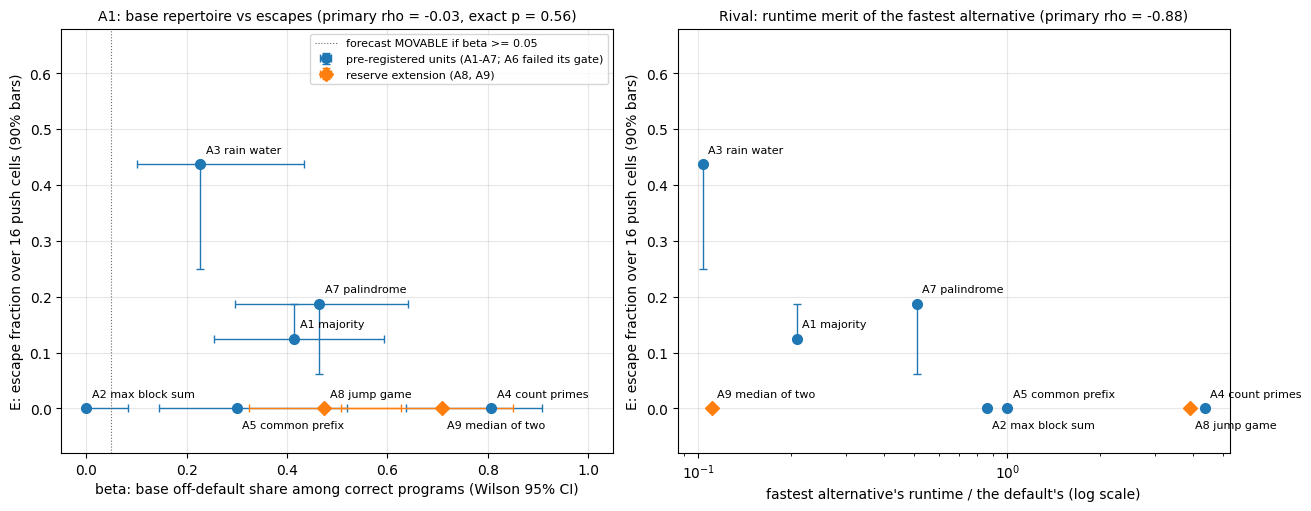

In [25]:
# Figure 1: claim A1 -- beta against E (fig1 of src/figures5.py, redrawn), next to the strongest trivial rival
t0 = time.time()
E_CI = {u: e_boot(u, P[u]["default"], P[u]["catalogue"]) for u in UNITS}
print(f"e_boot ({E_BOOT_N} resamples per unit) over {len(UNITS)} units: {time.time() - t0:.1f} s")
SHORT = {"A1": "majority", "A2": "max block sum", "A3": "rain water", "A4": "count primes", "A5": "common prefix",
         "A7": "palindrome", "A8": "jump game", "A9": "median of two"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, xkey, xlabel, title in (
        (axes[0], "beta", "beta: base off-default share among correct programs (Wilson 95% CI)",
         f"A1: base repertoire vs escapes (primary rho = {r_pri['a1']['rho_beta_E']:.2f}, "
         f"exact p = {r_pri['a1']['perm_p_one_sided']:.2f})"),
        (axes[1], "merit_runtime_min", "fastest alternative's runtime / the default's (log scale)",
         f"Rival: runtime merit of the fastest alternative (primary rho = "
         f"{r_pri['a1']['rivals']['merit_runtime_min']['rho_r_E']:.2f})")):
    xval = lambda u: P[u]["beta"] if xkey == "beta" else P[u]["rivals"][xkey]
    for kind, marker, lab in (("primary", "o", "pre-registered units (A1-A7; A6 failed its gate)"),
                              ("ext", "D", "reserve extension (A8, A9)")):
        us = [u for u in UNITS if (u in NEW_UNITS) == (kind == "primary")]
        x = np.array([xval(u) for u in us])
        y = np.array([summ[u]["outcome"]["E"] for u in us])
        ye = np.array([[max(0.0, y[i] - E_CI[u][0]), max(0.0, E_CI[u][1] - y[i])] for i, u in enumerate(us)]).T
        xe = (np.array([[x[i] - P[u]["beta_ci"][0], P[u]["beta_ci"][1] - x[i]] for i, u in enumerate(us)]).T
              if xkey == "beta" else None)
        ax.errorbar(x, y, xerr=xe, yerr=ye, fmt=marker, ms=7, capsize=3, lw=1, label=lab)
    # point labels; the immovable units (E = 0) alternate above / below their marker so neighbours stay readable
    zero = sorted([u for u in UNITS if summ[u]["outcome"]["E"] == 0], key=xval)
    for u in UNITS:
        dy = (-14 if zero.index(u) % 2 else 8) if u in zero else 8
        ax.annotate(f"{u} {SHORT.get(u, '')}", (xval(u), summ[u]["outcome"]["E"]), xytext=(4, dy),
                    textcoords="offset points", fontsize=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("E: escape fraction over 16 push cells (90% bars)")
    ax.set_ylim(-0.08, 0.68)
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
axes[0].axvline(BETA_MOVABLE, color="0.4", lw=0.8, ls=":", label="forecast MOVABLE if beta >= 0.05")
axes[0].set_xlim(-0.05, 1.05)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].set_xscale("log")
plt.show()

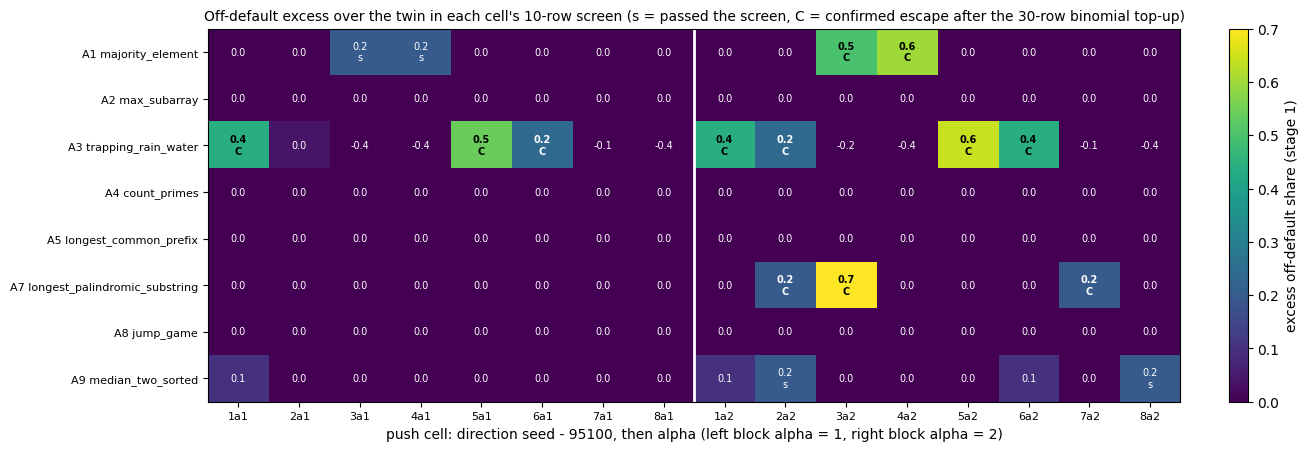

In [26]:
# Figure 2: per-direction escape outcomes (fig2 of src/figures5.py: same matrix and outcome categories, redrawn)
cols = [f"{s - 95100}a{int(a)}" for a in ALPHAS for s in ESC_SEEDS]
rows_, mat, cat_ = [], [], []
for t in UNITS:
    by = {(c["seed"], c["alpha"]): c for c in summ[t]["escape_cells"]}
    rows_.append(t)
    mat.append([round(by[(s, a)]["excess10"], 2) if by[(s, a)]["excess10"] is not None else 0.0
                for a in ALPHAS for s in ESC_SEEDS])
    cat_.append([("confirmed" if by[(s, a)]["confirmed"] else "screen pass" if by[(s, a)]["screen_pass"] else
                  "no escape") for a in ALPHAS for s in ESC_SEEDS])
fig, ax = plt.subplots(figsize=(13, 4.4), layout="constrained")
im = ax.imshow(np.array(mat), cmap="viridis", vmin=0, vmax=max(0.5, float(np.max(mat))), aspect="auto")
for i in range(len(rows_)):
    for j in range(len(cols)):
        mark = {"confirmed": "C", "screen pass": "s", "no escape": ""}[cat_[i][j]]
        ax.text(j, i, f"{mat[i][j]:.1f}\n{mark}" if mark else f"{mat[i][j]:.1f}", ha="center", va="center",
                fontsize=7, color="w" if mat[i][j] < 0.35 else "k", fontweight="bold" if mark == "C" else "normal")
ax.set_xticks(range(len(cols)), cols, fontsize=8)
ax.set_yticks(range(len(rows_)), [f"{u} {UNIT_DIRS[u].split('_', 1)[1]}" for u in rows_], fontsize=8)
ax.axvline(len(ESC_SEEDS) - 0.5, color="w", lw=2)
ax.set_xlabel("push cell: direction seed - 95100, then alpha (left block alpha = 1, right block alpha = 2)")
ax.set_title("Off-default excess over the twin in each cell's 10-row screen "
             "(s = passed the screen, C = confirmed escape after the 30-row binomial top-up)", fontsize=10)
fig.colorbar(im, ax=ax, label="excess off-default share (stage 1)")
plt.show()

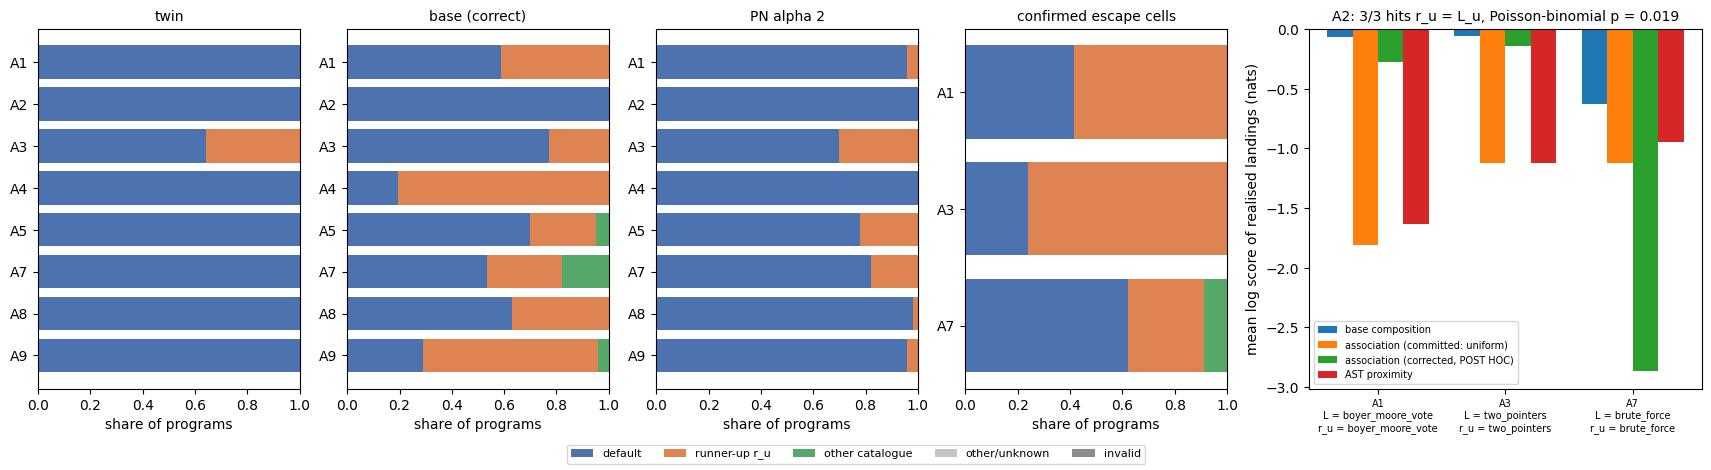

In [27]:
# Figure 3: program compositions per unit (fig3 of src/figures5.py, redrawn) and the A2 log scores per landing event
keys = ["default", "runner-up r_u", "other catalogue", "other/unknown", "invalid"]
colors = ["#4c72b0", "#dd8452", "#55a868", "#c4c4c4", "#8c8c8c"]
comps = {u: comp_rows(u, P, summ) for u in UNITS}
fig, axes = plt.subplots(1, 5, figsize=(17, 4.6), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.5]})
for ax, arm in zip(axes[:4], ("twin", "base (correct)", "PN alpha 2", "confirmed escape cells")):
    us = [u for u in UNITS if sum(comps[u][arm].values()) > 0]
    left = np.zeros(len(us))
    for k, col in zip(keys, colors):
        vals = np.array([comps[u][arm].get(k, 0) / sum(comps[u][arm].values()) for u in us])
        ax.barh(us, vals, left=left, color=col, label=k)
        left += vals
    ax.set_title(arm, fontsize=10)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_xlabel("share of programs")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5, fontsize=8)
# A2: mean log score of the realised landing labels under each forecast (higher = better forecast)
ax = axes[4]
ev_c = {e["unit"]: e for e in assoc["a2_assoc_corrected"]["primary"]["events"]}
evs = r_pri["a2"]["events"]
w = 0.2
for j, (lab, get) in enumerate((("base composition", lambda e: e["log_scores"]["base"]),
                                ("association (committed: uniform)", lambda e: e["log_scores"]["assoc"]),
                                ("association (corrected, POST HOC)", lambda e: ev_c[e["unit"]]["log_scores"]["assoc"]),
                                ("AST proximity", lambda e: e["log_scores"]["prox"]))):
    ax.bar(np.arange(len(evs)) + (j - 1.5) * w, [get(e) for e in evs], w, label=lab)
ax.set_xticks(range(len(evs)), [f"{e['unit']}\nL = {e['L']}\nr_u = {e['r']}" for e in evs], fontsize=7)
ax.set_ylabel("mean log score of realised landings (nats)")
ax.set_title(f"A2: {r_pri['a2']['hits']}/{r_pri['a2']['n_events']} hits r_u = L_u, "
             f"Poisson-binomial p = {r_pri['a2']['p_poisson_binomial']:.3f}", fontsize=10)
ax.legend(fontsize=7, loc="lower left")
plt.show()

## Takeaways

- **The base repertoire predicts where a push lands, but not whether it lands.**
  - **A2.** On all 3 units that moved (A1, A3, A7), the confirmed escapes landed exactly on the base model's runner-up r_u (Poisson-binomial p = 0.019). The base composition's log score beats AST proximity on every event, and beats the association prompt even after its post-hoc fix.
  - **A1.** β does not rank how movable a unit is: ρ = −0.03 on the primary set and −0.33 with the extension. The most diverse base units never escape: A4 count primes (β = 0.81), A9 median of two lists (β = 0.71) and A8 jump game (β = 0.47).
- **Trivial rivals track movability better than β.**
  - The runtime merit of the fastest alternative gives ρ = −0.88: the three units that move have an alternative at least about twice as fast as the default. The extension unit A9 breaks this.
  - The twin's own modal share gives ρ = −0.70.
- **Pushes rearrange the existing repertoire rather than invent.** No correct pushed program uses an algorithm the base model never wrote, correct or not (the repertoire check above). The artifact's separate novelty audit found no correct novel algorithm among its 6,854 correct programs.
- **Reproduction.** At the original resampling counts, every headline number recomputed in this notebook from the 4,640 labelled programs equals the artifact's recorded value, including the bootstrap intervals.
- **Scope.**
  - One model family, memorised LeetCode problems, and n = 6 primary units.
  - Power is about 0.46 for a true ρ of 0.6 even when pooled with panel B, so the A1 null is weak evidence on its own.
  - The pooled decision across panels is made in the next round from the artifact's `pooled_inputs.json`.